# Label Space Diffusion for Extreme Multi-Label Classification
### IE 643 Course Project &middot; Team TRANSFORMERS
### Dataset: AmazonCat-13K (1,186,239 train / 306,782 test documents, 13,330 labels)

## 1. Setup & Configuration

In [1]:
import importlib, subprocess, sys

def ensure(pip_name, import_name=None):
    try:
        importlib.import_module(import_name or pip_name)
    except ImportError:
        print(f"installing {pip_name} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=False)

ensure("faiss-cpu", "faiss")
ensure("ipywidgets")
ensure("joblib")
ensure("transformers")
ensure("peft")
print("dependencies ready")

installing faiss-cpu ...
dependencies ready


In [2]:
# peft refuses to import with Kaggle's old torchao (0.10); LoRA doesn't need torchao, so remove it
import importlib.metadata as _md
try:
    if tuple(int(x) for x in _md.version("torchao").split(".")[:2]) < (0, 16):
        subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=False)
        print("removed old torchao (not needed for LoRA)")
except _md.PackageNotFoundError:
    pass

removed old torchao (not needed for LoRA)


In [3]:
import os, math, time, random, json, gc, copy, hashlib, glob

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.decomposition import TruncatedSVD, PCA

SEED = 43
def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
seed_everything()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_GPU = torch.cuda.device_count() if DEVICE == "cuda" else 0
print("device:", DEVICE, "| GPUs:", N_GPU)
if DEVICE == "cuda":
    for i in range(N_GPU):
        print("  GPU", i, torch.cuda.get_device_name(i))

OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "/tmp/working"
CKPT_DIR = os.path.join(OUT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(OUT_DIR, "results")
HF_CACHE_DIR = "/tmp/hf_cache"        # not under /kaggle/working, so the ~2.5 GB download isn't saved as output
EMB_CACHE_DIR = "/tmp/ldxmc_cache"    # cached BERT embeddings (session only; ~1-2 GB)
for d in (CKPT_DIR, RESULTS_DIR, HF_CACHE_DIR, EMB_CACHE_DIR):
    os.makedirs(d, exist_ok=True)
print("outputs ->", OUT_DIR)

device: cuda | GPUs: 2
  GPU 0 Tesla T4
  GPU 1 Tesla T4
outputs -> /kaggle/working


In [4]:
# ============================================================================
# THE ONE SWITCH THAT MATTERS
#   True  -> tiny synthetic dataset + bert-tiny, minutes end-to-end (smoke test)
#   False -> the real AmazonCat-13K run with bert-base-uncased
# ============================================================================
DEBUG_MODE = False

CONFIG = dict(
    # ---- data ----
    hf_dataset_name    = "pietrolesci/amazoncat-13k",
    num_labels         = 13330,
    train_fraction     = 1.00,      # v2.2: the full 1.19M training pool (v1 used 0.30, v2/v2.1 0.50)
    val_fraction       = 0.015,     # ~17.8K docs carved out of the training pool (same size as v2/v2.1's validation set)
    test_eval_size     = 30000,     # test docs evaluated (None = all 306,782; same subsample size as v1)
    tail_threshold     = 9,
    head_threshold     = 100,
    propensity_A       = 0.6,
    propensity_B       = 2.6,

    # ---- BERT document encoder ----
    bert_model         = "bert-base-uncased",
    bert_mode          = "finetune",  # "finetune" (recommended) | "frozen" (no fine-tuning; much weaker, but fast)
    max_len            = 256,         # v2.2: was 128, which truncated 50% of documents
    bert_batch         = 64,
    bert_epochs        = 1,
    bert_max_train_docs= None,        # cap on docs used for BERT fine-tuning (None = all); e.g. 600000 halves the BERT time
    bert_tuning        = "lora",      # v2.2: "lora" (low-rank adapters, BERT weights frozen) | "full"
    lora_r             = 16,
    lora_alpha         = 32,
    lora_dropout       = 0.1,
    lora_targets       = ("query", "key", "value", "dense"),   # attention projections + feed-forward layers
    lora_lr            = 3e-4,        # LoRA adapters need a larger LR than full fine-tuning
    bert_lr            = 5e-5,        # used only when bert_tuning = "full"
    head_lr            = 2e-3,        # the 13,330-way head needs a larger LR than the pretrained body
    bert_warmup        = 0.05,
    bert_wd            = 0.01,
    encode_batch       = 128,
    fp16               = True,
    reuse_checkpoints  = True,        # skip fine-tuning / encoding if this session already produced them

    bert_ckpt_path     = None,        # explicit path to a fine-tuned bert_xmc_*.pt (else /kaggle/input is searched)

    # ---- label space ----
    d_lat              = 128,
    warm_start_labels  = True,        # BERT label centroids (PIFA) + co-occurrence SVD
    cooc_dims          = 64,
    cooc_weight        = 0.5,
    label_table        = "full",      # "full" | "gated" | "pos_only" | "frozen"; re-selected on validation if table_mode_search
    table_mode_search  = True,        # short comparison of table_modes on the full validation set
    table_modes        = ("full", "gated", "frozen"),
    gate_freq          = 50,          # gated mode: negatives' push-away is off for tail labels, ramps to full at this many train docs
    reuse_v21_main     = False,       # v2.1's model was trained on a different encoder; only valid if data/BERT settings match

    # ---- set denoiser (transformer) ----
    n_slots            = 8,           # label slots generated per sample (avg 5.04 labels/doc; extras are NULL)
    d_model            = 384,
    n_layers           = 4,
    n_heads            = 6,
    n_cond_tokens      = 4,           # the document embedding is also given to attention as this many tokens
    self_cond          = True,

    # ---- diffusion ----
    T_steps            = 1000,
    ddim_steps         = 10,
    cond_drop_prob     = 0.10,
    guidance_scale     = 1.5,         # re-selected on validation in Section 8
    eta                = 0.0,         # DDIM stochasticity, re-selected on validation
    clamp              = "none",      # "none" | "hard" (snap x0 to nearest label each step); v2 showed "hard" hurts P@5
    K_samples          = 4,           # label SETS sampled per document (4 x 8 slots = 32 label draws)
    retrieval_tau      = 0.1,         # re-selected on validation
    score_rule         = "presence_tb", # "presence" (v2) | "presence_tb" | "logabsent" | "count" | "traj"; re-selected on validation
    select_metric      = "nDCG@5+PSnDCG@5",  # validation criterion ('+'-joined); v2 used P@5 alone, which traded away P@1
    tail_boost         = 0.0,         # beta in score * (1/propensity)^beta; 0 = plain ranking
    round_weight       = 1.0,
    round_tau          = 0.1,
    null_weight        = 0.5,         # loss weight of NULL (padding) slots
    tail_weight_power  = 0.35,        # label weights (1/p)^power in the losses (same as v1)

    # ---- diffusion training ----
    batch_size         = 512,         # documents per step (each gives n_slots targets)
    epochs             = 20,          # 2x the data of v2.1, so 20 epochs = ~1.3x v2.1's optimisation steps
    lr                 = 1e-3,
    weight_decay       = 1e-4,
    eval_every         = 2,           # epochs between validation checks (best checkpoint by select_metric is kept)
    ablation_epochs    = 6,
    ablation_max_docs  = 150000,
    run_inference_ablations = False,  # already reported from the v2.1 run
    run_training_ablations  = False,

    # ---- deterministic set-MLP baseline ----
    mlp_hidden         = 1024,
    mlp_epochs         = 10,
    mlp_lr             = 1e-3,

    # ---- eval ----
    ks                 = (1, 3, 5),
    val_eval_docs      = 2000,
)

if DEBUG_MODE:
    CONFIG.update(dict(
        num_labels=500, train_fraction=1.0, val_fraction=0.1, test_eval_size=600, head_threshold=30,
        bert_model="prajjwal1/bert-tiny", max_len=32, lora_lr=1e-3, bert_batch=64, bert_epochs=3, head_lr=5e-3, bert_lr=1e-4,
        d_lat=32, cooc_dims=16, n_slots=6, d_model=128, n_layers=2, n_heads=4,
        T_steps=200, batch_size=256, epochs=12, eval_every=3, ablation_epochs=4, ablation_max_docs=4000,
        val_eval_docs=400, gate_freq=20, mlp_hidden=256, mlp_epochs=8, run_inference_ablations=True, run_training_ablations=True,
    ))

USE_AMP = (DEVICE == "cuda") and CONFIG["fp16"]
AMP_DTYPE = torch.float16
DEVICE_TYPE = "cuda" if DEVICE == "cuda" else "cpu"

def autocast():
    return torch.autocast(device_type=DEVICE_TYPE, dtype=AMP_DTYPE, enabled=USE_AMP)

def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

print(json.dumps(CONFIG, indent=2))

{
  "hf_dataset_name": "pietrolesci/amazoncat-13k",
  "num_labels": 13330,
  "train_fraction": 1.0,
  "val_fraction": 0.015,
  "test_eval_size": 30000,
  "tail_threshold": 9,
  "head_threshold": 100,
  "propensity_A": 0.6,
  "propensity_B": 2.6,
  "bert_model": "bert-base-uncased",
  "bert_mode": "finetune",
  "max_len": 256,
  "bert_batch": 64,
  "bert_epochs": 1,
  "bert_max_train_docs": null,
  "bert_tuning": "lora",
  "lora_r": 16,
  "lora_alpha": 32,
  "lora_dropout": 0.1,
  "lora_targets": [
    "query",
    "key",
    "value",
    "dense"
  ],
  "lora_lr": 0.0003,
  "bert_lr": 5e-05,
  "head_lr": 0.002,
  "bert_warmup": 0.05,
  "bert_wd": 0.01,
  "encode_batch": 128,
  "fp16": true,
  "reuse_checkpoints": true,
  "bert_ckpt_path": null,
  "d_lat": 128,
  "warm_start_labels": true,
  "cooc_dims": 64,
  "cooc_weight": 0.5,
  "label_table": "full",
  "table_mode_search": true,
  "table_modes": [
    "full",
    "gated",
    "frozen"
  ],
  "gate_freq": 50,
  "reuse_v21_main": false

## 2. Data Acquisition &mdash; AmazonCat-13K

Same source and loader as v1 (`pietrolesci/amazoncat-13k` on the Hugging Face Hub, identical to the
Extreme Classification Repository release). We use the raw `text` field (title followed by the
product description) and the `target_ind` label lists.

In [5]:
def find_column(columns, candidates):
    for c in candidates:
        if c in columns:
            return c
    for c in columns:
        for cand in candidates:
            if cand.lower() in c.lower():
                return c
    return None


def to_label_ids(row, num_labels):
    arr = np.asarray(row)
    if arr.ndim == 1 and arr.size == num_labels and arr.size > 64 and set(np.unique(arr).tolist()) <= {0, 1}:
        return np.nonzero(arr)[0].astype(int).tolist()
    return [int(x) for x in row]


def load_amazoncat13k(cfg):
    try:
        from datasets import load_dataset
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=True)
        from datasets import load_dataset

    ds = load_dataset(cfg["hf_dataset_name"], cache_dir=HF_CACHE_DIR)
    cols = ds["train"].column_names
    text_col = find_column(cols, ["text", "title_and_content", "content", "title"])
    label_col = find_column(cols, ["target_ind", "labels", "label", "target"])
    print("columns:", cols, "| text =", text_col, "| labels =", label_col)
    assert text_col and label_col

    keep = [text_col, label_col]
    train_full = ds["train"].select_columns(keep)
    test_full = ds["test"].select_columns(keep)

    n_use = max(1000, int(cfg["train_fraction"] * len(train_full)))
    train_full = train_full.shuffle(seed=SEED).select(range(min(n_use, len(train_full))))
    split = train_full.train_test_split(test_size=cfg["val_fraction"], seed=SEED)
    train_split, val_split = split["train"], split["test"]

    n_test = len(test_full) if cfg["test_eval_size"] is None else min(cfg["test_eval_size"], len(test_full))
    test_split = test_full.shuffle(seed=SEED).select(range(n_test))

    def unpack(part):
        texts = [str(t) for t in part[text_col]]
        labels = [to_label_ids(r, cfg["num_labels"]) for r in part[label_col]]
        return texts, labels

    tr_t, tr_l = unpack(train_split)
    va_t, va_l = unpack(val_split)
    te_t, te_l = unpack(test_split)
    max_lab = max((max(l) for part in (tr_l, va_l, te_l) for l in part if l), default=0)
    if max_lab >= cfg["num_labels"]:
        print(f"NOTE: bumping num_labels {cfg['num_labels']} -> {max_lab + 1}")
        cfg["num_labels"] = max_lab + 1
    return tr_t, tr_l, va_t, va_l, te_t, te_l, None

In [6]:
def make_informative_split(n, num_labels, vocab_size, seed, sig_words=3, zipf_a=1.15):
    # Synthetic XMC data for DEBUG_MODE: each label owns a few signature words.
    rng = np.random.default_rng(seed)
    sig_rng = np.random.default_rng(12345)
    signatures = sig_rng.integers(0, vocab_size, size=(num_labels, sig_words))
    p = 1.0 / np.arange(1, num_labels + 1) ** zipf_a
    p /= p.sum()
    perm = sig_rng.permutation(num_labels)
    texts, labels_list = [], []
    for _ in range(n):
        k = int(rng.choice([1, 2, 2, 3, 3, 4]))
        labs = sorted(set(perm[rng.choice(num_labels, size=k, p=p)].tolist()))
        words = []
        for l in labs:
            words.extend(signatures[l][rng.choice(sig_words, size=2, replace=False)].tolist())
        words.extend(rng.integers(0, vocab_size, size=int(rng.integers(3, 7))).tolist())
        rng.shuffle(words)
        texts.append(" ".join(f"w{w}" for w in words))
        labels_list.append(labs)
    return texts, labels_list


def load_debug_data(cfg):
    V = 1500
    tr_t, tr_l = make_informative_split(8000, cfg["num_labels"], V, seed=1)
    va_t, va_l = make_informative_split(800, cfg["num_labels"], V, seed=2)
    te_t, te_l = make_informative_split(cfg["test_eval_size"], cfg["num_labels"], V, seed=3)
    return tr_t, tr_l, va_t, va_l, te_t, te_l, None


t0 = time.time()
if DEBUG_MODE:
    (train_texts, train_labels, val_texts, val_labels, test_texts, test_labels, LABEL_NAMES) = load_debug_data(CONFIG)
else:
    (train_texts, train_labels, val_texts, val_labels, test_texts, test_labels, LABEL_NAMES) = load_amazoncat13k(CONFIG)
L_ = CONFIG["num_labels"]
print(f"data ready in {time.time()-t0:.1f}s | train={len(train_texts)} val={len(val_texts)} test={len(test_texts)} | labels={L_}")
print("example:", train_labels[0], "::", train_texts[0][:120])

README.md:   0%|          | 0.00/3.88k [00:00<?, ?B/s]

data/train-00000-of-00007-cc1e50d411227c(…): reconstructing file:   0%|          |  0.00B /  291MB            

data/train-00000-of-00007-cc1e50d411227c(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-f5d948dab69d63(…): reconstructing file:   0%|          |  0.00B /  292MB            

data/train-00001-of-00007-f5d948dab69d63(…): downloading bytes:           |  0.00B            

...

data/test-00001-of-00002-5ab04dbbce18d60(…): reconstructing file:   0%|          |  0.00B /  266MB            

data/test-00001-of-00002-5ab04dbbce18d60(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1186239 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/306782 [00:00<?, ? examples/s]

columns: ['uid_original', 'title', 'content', 'target_ind', 'target_rel', 'text', 'uid'] | text = text | labels = target_ind
data ready in 172.5s | train=1168445 val=17794 test=30000 | labels=13330
example: [945, 4354, 11235, 11492] :: Cap Barbell Solid Chrome Bar

5 Olympic Bar is designed for balance and long lasting performance with a compact design s


## 3. Label Statistics & Propensities

Unchanged from v1: propensity model of Jain, Prabhu & Varma (KDD 2016),
$p_\ell = 1/(1 + C\,(N_\ell + B)^{-A})$, $C = (\ln N - 1)(B+1)^A$, $(A,B) = (0.6, 2.6)$.
Counts come from the sampled training set, so with `train_fraction < 1` more labels count as tail
than in the full data.

labels=13330 | tail: 3960 (29.7%) | torso: 5805 | head: 3553 | absent from train sample: 12
avg labels / train doc: 5.04 | docs with > n_slots=8 labels: 12.3%


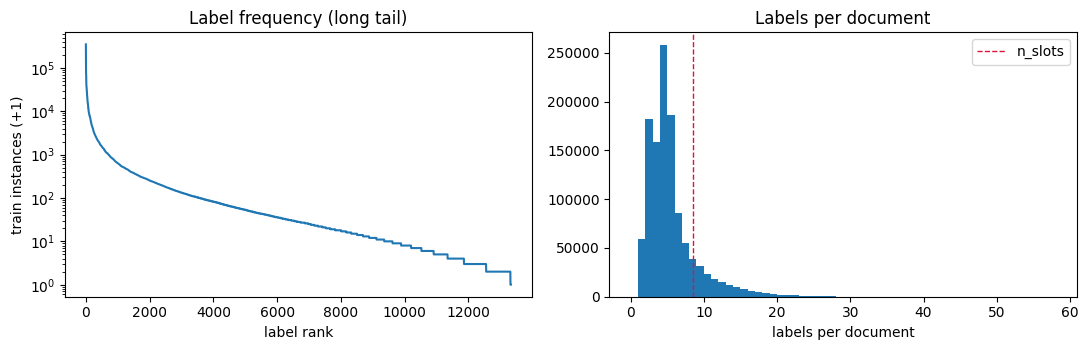

In [7]:
def compute_propensities(train_labels_list, num_labels, A, B):
    N = len(train_labels_list)
    freq = np.zeros(num_labels, dtype=np.float64)
    for labs in train_labels_list:
        for l in labs:
            freq[l] += 1
    C = (np.log(N) - 1) * (B + 1) ** A
    p = 1.0 / (1.0 + C * (freq + B) ** (-A))
    return p, freq

PROPENSITY, LABEL_FREQ = compute_propensities(train_labels, L_, CONFIG["propensity_A"], CONFIG["propensity_B"])
TAIL_MASK  = (LABEL_FREQ >= 1) & (LABEL_FREQ <= CONFIG["tail_threshold"])
HEAD_MASK  = LABEL_FREQ >= CONFIG["head_threshold"]
TORSO_MASK = (LABEL_FREQ > CONFIG["tail_threshold"]) & (LABEL_FREQ < CONFIG["head_threshold"])
ABSENT     = LABEL_FREQ == 0
print(f"labels={L_} | tail: {TAIL_MASK.sum()} ({100*TAIL_MASK.mean():.1f}%) | torso: {TORSO_MASK.sum()} | "
      f"head: {HEAD_MASK.sum()} | absent from train sample: {ABSENT.sum()}")
print(f"avg labels / train doc: {np.mean([len(l) for l in train_labels]):.2f} | "
      f"docs with > n_slots={CONFIG['n_slots']} labels: {100*np.mean([len(l) > CONFIG['n_slots'] for l in train_labels]):.1f}%")

# shared GPU tensors used by both models' ranking functions
ABSENT_T = torch.from_numpy(ABSENT).to(DEVICE)
LOG_INV_PROP_T = torch.from_numpy(np.log(1.0 / PROPENSITY).astype(np.float32)).to(DEVICE)

order = np.argsort(-LABEL_FREQ)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(np.arange(1, len(order) + 1), LABEL_FREQ[order] + 1)
axes[0].set_yscale("log"); axes[0].set_xlabel("label rank"); axes[0].set_ylabel("train instances (+1)")
axes[0].set_title("Label frequency (long tail)")
axes[1].hist([len(l) for l in train_labels], bins=range(0, max(12, max(len(l) for l in train_labels) + 2)))
axes[1].axvline(CONFIG["n_slots"] + 0.5, color="crimson", ls="--", lw=1, label="n_slots")
axes[1].set_xlabel("labels per document"); axes[1].set_title("Labels per document"); axes[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "label_statistics.png"), dpi=130); plt.show()

## 4. BERT Document Encoder

**Model.** `bert-base-uncased` (Devlin et al., 2019); a document is encoded as the
attention-masked **mean of the last-layer token states**, $h \in \mathbb{R}^{768}$.

**Fine-tuning.** BERT plus a linear $768 \to L$ head is fine-tuned with binary cross-entropy on the
training split (the standard BERT-for-XMC recipe, e.g. X-Transformer / LightXML, without their label
clustering). Practical details that matter on a T4:
- mixed precision (fp16), `max_len=128`, per-batch trimming of padding, both GPUs via `DataParallel` if present;
- separate learning rates: `5e-5` for the pretrained body, `2e-3` for the freshly initialised head;
- the head's bias is initialised to the **log-odds of each label's prior**, so training does not waste
  its first thousand steps learning that 13,325 of 13,330 labels are negative (v1's baseline started at a BCE of 190/doc for this reason).

**One encoder, two models.** After fine-tuning, $h$ is computed **once** for every train/val/test
document and cached (the plan from the prep presentation). Then:
- the **baseline** is that same fine-tuned BERT + linear head (its predictions are `head(h)`);
- the **diffusion model** is conditioned on the same cached $h$, and never uses the head.

So the comparison still holds everything fixed except the prediction mechanism. (The encoder was
*trained* with an auxiliary $L$-way head; inference on the diffusion path does not use it.)

In [8]:
from transformers import AutoTokenizer, AutoModel
try:
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error()
except Exception:
    pass

TOKENIZER = AutoTokenizer.from_pretrained(CONFIG["bert_model"])
PAD_ID = TOKENIZER.pad_token_id if TOKENIZER.pad_token_id is not None else 0


def tokenize_all(texts, max_len, chunk=20000, verbose=True):
    max_chars = max_len * 12                      # pre-truncate very long descriptions: much faster tokenization
    out = np.full((len(texts), max_len), PAD_ID, dtype=np.int32)
    t0 = time.time()
    for s in range(0, len(texts), chunk):
        batch = [t[:max_chars] for t in texts[s:s + chunk]]
        enc = TOKENIZER(batch, max_length=max_len, truncation=True, padding="max_length")["input_ids"]
        out[s:s + len(batch)] = np.asarray(enc, dtype=np.int32)
    if verbose:
        print(f"  tokenized {len(texts):,} docs in {time.time()-t0:.0f}s")
    return out


def to_device_batch(ids_np):
    ids = torch.from_numpy(ids_np.astype(np.int64))
    Lb = max(int((ids != PAD_ID).sum(1).max()), 1)    # trim padding to the longest doc in the batch
    ids = ids[:, :Lb].to(DEVICE, non_blocking=True)
    return ids, (ids != PAD_ID).long()


train_ids_np = tokenize_all(train_texts, CONFIG["max_len"])
val_ids_np   = tokenize_all(val_texts,   CONFIG["max_len"])
test_ids_np  = tokenize_all(test_texts,  CONFIG["max_len"])
lens = (train_ids_np != PAD_ID).sum(1)
print(f"token length: median {np.median(lens):.0f}, {100*np.mean(lens >= CONFIG['max_len']):.0f}% truncated at {CONFIG['max_len']}")
del train_texts, val_texts
gc.collect()

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

  tokenized 1,168,445 docs in 329s
  tokenized 17,794 docs in 5s
  tokenized 30,000 docs in 8s
token length: median 128, 28% truncated at 256


0

In [9]:
class BertXMC(nn.Module):
    def __init__(self, name, num_labels, dropout=0.1):
        super().__init__()
        self.bert = AutoModel.from_pretrained(name)
        self.hidden = self.bert.config.hidden_size
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(self.hidden, num_labels)

    def forward(self, ids, mask, pooled_only=False):
        out = self.bert(input_ids=ids, attention_mask=mask).last_hidden_state
        m = mask.unsqueeze(-1).to(out.dtype)
        h = (out * m).sum(1) / m.sum(1).clamp(min=1.0)
        if pooled_only:
            return h
        return self.head(self.drop(h))


def labels_to_dense(labels_batch, num_labels, device):
    y = torch.zeros(len(labels_batch), num_labels, device=device)
    rows = [i for i, l in enumerate(labels_batch) for _ in l]
    cols = [c for l in labels_batch for c in l]
    if rows:
        y[torch.tensor(rows, device=device), torch.tensor(cols, device=device)] = 1.0
    return y


def init_head_bias(head, freq, n_docs):
    prior = np.clip((freq + 0.1) / n_docs, 1e-7, 0.5)
    with torch.no_grad():
        head.bias.copy_(torch.from_numpy(np.log(prior / (1 - prior)).astype(np.float32)))


def finetune_bert(model, ids_np, labels_list, cfg):
    n_all = len(labels_list)
    n = n_all if cfg["bert_max_train_docs"] is None else min(cfg["bert_max_train_docs"], n_all)
    rng = np.random.default_rng(SEED)
    bs = cfg["bert_batch"]
    steps_per_epoch = math.ceil(n / bs)
    total = cfg["bert_epochs"] * steps_per_epoch
    warm = max(1, int(cfg["bert_warmup"] * total))

    use_lora = cfg.get("bert_tuning", "full") == "lora"
    if use_lora:
        from peft import LoraConfig, get_peft_model
        lcfg = LoraConfig(r=cfg["lora_r"], lora_alpha=cfg["lora_alpha"], lora_dropout=cfg["lora_dropout"],
                          target_modules=list(cfg["lora_targets"]), bias="none")
        model.bert = get_peft_model(model.bert, lcfg)          # base BERT weights frozen; only the adapters train
        n_tr = sum(p.numel() for p in model.bert.parameters() if p.requires_grad)
        print(f"LoRA: r={cfg['lora_r']}, alpha={cfg['lora_alpha']}, targets={cfg['lora_targets']} -> "
              f"{n_tr:,} trainable BERT parameters ({100*n_tr/sum(p.numel() for p in model.bert.parameters()):.2f}%)")
    body_lr = cfg["lora_lr"] if use_lora else cfg["bert_lr"]
    no_decay = lambda nm: nm.endswith("bias") or "LayerNorm" in nm or "layer_norm" in nm
    trainable = [(nm, p) for nm, p in model.bert.named_parameters() if p.requires_grad]
    groups = [
        {"params": [p for nm, p in trainable if not no_decay(nm)], "lr": body_lr, "weight_decay": cfg["bert_wd"]},
        {"params": [p for nm, p in trainable if no_decay(nm)],     "lr": body_lr, "weight_decay": 0.0},
        {"params": list(model.head.parameters()),                  "lr": cfg["head_lr"], "weight_decay": 0.0},
    ]
    opt = torch.optim.AdamW([g for g in groups if g["params"]])
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else max(0.0, (total - s) / max(1, total - warm)))
    scaler = make_scaler()
    net = nn.DataParallel(model) if N_GPU > 1 else model
    print(f"fine-tuning {cfg['bert_model']} on {n:,} docs x {cfg['bert_epochs']} epoch(s) = {total:,} steps (batch {bs})")

    step, t0, run = 0, time.time(), 0.0
    for epoch in range(cfg["bert_epochs"]):
        model.train()
        perm = rng.permutation(n_all)[:n]
        for s in range(steps_per_epoch):
            idx = perm[s * bs:(s + 1) * bs]
            ids, mask = to_device_batch(ids_np[idx])
            y = labels_to_dense([labels_list[i] for i in idx], L_, DEVICE)
            with autocast():
                logits = net(ids, mask)
            loss = F.binary_cross_entropy_with_logits(logits.float(), y, reduction="sum") / len(idx)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            lv = loss.item()
            run = 0.98 * run + 0.02 * lv if step else lv
            step += 1
            if step % 200 == 0 or step == total:
                el = time.time() - t0
                print(f"  step {step:6d}/{total}  bce/doc={run:.3f}  {step*bs/el:.0f} docs/s  "
                      f"elapsed {el/60:.1f} min  ETA {(total-step)*el/step/60:.1f} min")
    if use_lora:
        model.bert = model.bert.merge_and_unload()            # fold adapters into the weights: plain BERT again, no inference overhead
    model.eval()
    return model


@torch.no_grad()
def encode_docs(model, ids_np, bs, verbose=True):
    model.eval()
    net = nn.DataParallel(model) if N_GPU > 1 else model
    order = np.argsort(-(ids_np != PAD_ID).sum(1))     # length-sorted batches = less padding
    H = np.zeros((len(ids_np), model.hidden), dtype=np.float16)
    t0 = time.time()
    for s in range(0, len(order), bs):
        idx = order[s:s + bs]
        ids, mask = to_device_batch(ids_np[idx])
        with autocast():
            h = net(ids, mask, pooled_only=True)
        H[idx] = h.float().cpu().numpy().astype(np.float16)
    if verbose:
        print(f"  encoded {len(ids_np):,} docs in {time.time()-t0:.0f}s")
    return H

In [10]:
bert_xmc = BertXMC(CONFIG["bert_model"], L_).to(DEVICE)
init_head_bias(bert_xmc.head, LABEL_FREQ, len(train_labels))
D_COND = bert_xmc.hidden
print(f"BERT parameters: {sum(p.numel() for p in bert_xmc.bert.parameters()):,} | head: {sum(p.numel() for p in bert_xmc.head.parameters()):,}")

tag = hashlib.md5(json.dumps([CONFIG[k] for k in ("bert_model", "bert_mode", "max_len", "train_fraction",
                                                   "val_fraction", "test_eval_size", "bert_epochs",
                                                   "bert_max_train_docs")] + [DEBUG_MODE]
                     + ([CONFIG["bert_tuning"], CONFIG["lora_r"], list(CONFIG["lora_targets"])] if CONFIG["bert_tuning"] != "full" else [])
                     ).encode()).hexdigest()[:10]
BERT_CKPT = os.path.join(CKPT_DIR, f"bert_xmc_{tag}.pt")
EMB_CACHE = os.path.join(EMB_CACHE_DIR, f"emb_{tag}.npz")

def find_bert_checkpoint():
    if CONFIG["bert_ckpt_path"]:
        return CONFIG["bert_ckpt_path"]
    if os.path.exists(BERT_CKPT):
        return BERT_CKPT
    hits = sorted(glob.glob(f"/kaggle/input/**/bert_xmc_{tag}.pt", recursive=True))
    if not hits:
        seen = sorted(glob.glob("/kaggle/input/**/*.pt", recursive=True))
        print(f"looking for bert_xmc_{tag}.pt under /kaggle/input - .pt files visible there:", seen if seen else "NONE (no input attached?)")
    if not hits and glob.glob("/kaggle/input/**/bert_xmc_*.pt", recursive=True):
        print("NOTE: found bert_xmc_*.pt under /kaggle/input but with a different settings tag than", tag,
              "- data/BERT settings differ from that run, so it is NOT reused (the split would not match).")
    return hits[0] if hits else None

t0 = time.time()
if CONFIG["bert_mode"] == "finetune":
    ckpt_found = find_bert_checkpoint() if CONFIG["reuse_checkpoints"] else None
    if ckpt_found:
        bert_xmc.load_state_dict(torch.load(ckpt_found, map_location=DEVICE))
        print("loaded fine-tuned encoder from", ckpt_found)
    else:
        print("no fine-tuned checkpoint found -> fine-tuning BERT from scratch")
        finetune_bert(bert_xmc, train_ids_np, train_labels, CONFIG)
        torch.save(bert_xmc.state_dict(), BERT_CKPT)
        print("saved", BERT_CKPT)
print(f"encoder stage done in {(time.time()-t0)/60:.1f} min")

if CONFIG["reuse_checkpoints"] and os.path.exists(EMB_CACHE):
    z = np.load(EMB_CACHE)
    train_H, val_H, test_H = z["train"], z["val"], z["test"]
    print("loaded cached embeddings", EMB_CACHE)
else:
    print("encoding documents ...")
    train_H = encode_docs(bert_xmc, train_ids_np, CONFIG["encode_batch"])
    val_H   = encode_docs(bert_xmc, val_ids_np,   CONFIG["encode_batch"])
    test_H  = encode_docs(bert_xmc, test_ids_np,  CONFIG["encode_batch"])
    np.savez(EMB_CACHE, train=train_H, val=val_H, test=test_H)
print("embeddings:", train_H.shape, val_H.shape, test_H.shape, "| finite:", bool(np.isfinite(train_H).all()))

if DEVICE == "cuda":
    torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BERT parameters: 109,482,240 | head: 10,250,770
looking for bert_xmc_2cefffbdfe.pt under /kaggle/input - .pt files visible there: NONE (no input attached?)
no fine-tuned checkpoint found -> fine-tuning BERT from scratch
LoRA: r=16, alpha=32, targets=('query', 'key', 'value', 'dense') -> 2,678,784 trainable BERT parameters (2.39%)
fine-tuning bert-base-uncased on 1,168,445 docs x 1 epoch(s) = 18,257 steps (batch 64)
  step    200/18257  bce/doc=24.062  106 docs/s  elapsed 2.0 min  ETA 181.1 min
  step    400/18257  bce/doc=18.288  107 docs/s  elapsed 4.0 min  ETA 177.7 min
  step    600/18257  bce/doc=15.300  107 docs/s  elapsed 6.0 min  ETA 175.4 min
  step    800/18257  bce/doc=14.210  108 docs/s  elapsed 7.9 min  ETA 173.1 min
  step   1000/18257  bce/doc=13.397  108 docs/s  elapsed 9.9 min  ETA 170.9 min
  step   1200/18257  bce/doc=12.779  108 docs/s  elapsed 11.9 min  ETA 168.8 min
  step   1400/18257  bce/doc=12.022  108 docs/s  elapsed 13.8 min  ETA 166.6 min
  step   1600/18257

In [11]:
# The baseline lives on top of the cached embeddings: predictions = head(h).
# In "frozen" mode the head was never trained, so fit it here as a linear probe.
def train_linear_head(head, H, labels_list, epochs=5, bs=1024, lr=2e-3):
    opt = torch.optim.Adam(head.parameters(), lr=lr)
    Ht = torch.from_numpy(H).to(DEVICE)
    for ep in range(epochs):
        perm = np.random.permutation(len(labels_list)); tot = 0.0
        for s in range(0, len(perm), bs):
            idx = perm[s:s + bs]
            y = labels_to_dense([labels_list[i] for i in idx], L_, DEVICE)
            loss = F.binary_cross_entropy_with_logits(head(Ht[idx].float()), y, reduction="sum") / len(idx)
            opt.zero_grad(); loss.backward(); opt.step(); tot += float(loss) * len(idx)
        print(f"  linear probe epoch {ep+1}/{epochs}: bce/doc={tot/len(perm):.3f}")
    del Ht

if CONFIG["bert_mode"] == "frozen":
    train_linear_head(bert_xmc.head, train_H, train_labels)

# GPU copies of the cached embeddings (fp16) for fast batching
TRAIN_H = torch.from_numpy(train_H).to(DEVICE)
VAL_H   = torch.from_numpy(val_H).to(DEVICE)
TEST_H  = torch.from_numpy(test_H).to(DEVICE)

## 5. Label-Space Representation

As in v1, label $\ell$ has a trainable $w_\ell \in \mathbb{R}^{d_{lat}}$ with effective embedding
$e_\ell = \sqrt{d_{lat}}\, w_\ell/\lVert w_\ell\rVert$, plus one extra **NULL** row ($\ell = L$) that fills
unused slots of a document's label set.

**Warm start, now from BERT.** For every label, take the normalised sum of the (normalised) BERT
embeddings of its positive training documents &mdash; *positive-instance feature aggregation* (PIFA),
the label representation used by X-Transformer / PECOS (Chang et al., 2020). Concatenate it with a
co-occurrence SVD of $Y_{train}$ and project with PCA to $d_{lat}$. Two labels then start close if their
documents *read alike* or *co-occur*. This matters most for tail labels: a label with 2 training
documents still gets a meaningful position from those 2 documents' text, instead of a near-empty
co-occurrence row.

In [12]:
def build_label_indicator(labels_list, num_labels):
    rows = [i for i, labs in enumerate(labels_list) for _ in labs]
    cols = [l for labs in labels_list for l in labs]
    return sp.csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(len(labels_list), num_labels))

Y_train = build_label_indicator(train_labels, L_)


def warm_start_label_embeddings(Y, H, d_lat, cooc_dims, cooc_weight, seed=SEED):
    present = np.asarray(Y.sum(0)).ravel() > 0
    Hn = H.astype(np.float32)
    Hn /= np.linalg.norm(Hn, axis=1, keepdims=True) + 1e-8
    C = np.asarray(Y.T @ Hn)                                       # (L, 768) PIFA centroids
    C /= np.linalg.norm(C, axis=1, keepdims=True) + 1e-8
    del Hn
    k = min(cooc_dims, Y.shape[1] - 1)
    V = TruncatedSVD(n_components=k, random_state=seed).fit(Y).components_.T.astype(np.float32)   # (L, k)
    V /= np.linalg.norm(V, axis=1, keepdims=True) + 1e-8
    feats = np.hstack([C, cooc_weight * V])
    pca = PCA(n_components=d_lat, random_state=seed).fit(feats[present])
    init = pca.transform(feats).astype(np.float32)
    rng = np.random.default_rng(seed)
    init[~present] = rng.standard_normal(((~present).sum(), d_lat)).astype(np.float32)
    null_row = rng.standard_normal((1, d_lat)).astype(np.float32)   # NULL label
    init = np.vstack([init, null_row])
    init /= np.linalg.norm(init, axis=1, keepdims=True)
    return init, float(pca.explained_variance_ratio_.sum())


def random_label_init(num_rows, d_lat, seed=SEED):
    w = np.random.default_rng(seed).standard_normal((num_rows, d_lat)).astype(np.float32)
    return w / np.linalg.norm(w, axis=1, keepdims=True)

if CONFIG["warm_start_labels"]:
    label_init, evr = warm_start_label_embeddings(Y_train, train_H, CONFIG["d_lat"], CONFIG["cooc_dims"], CONFIG["cooc_weight"])
    print(f"BERT-PIFA + co-occurrence warm start: PCA explained variance = {evr:.3f}")
else:
    label_init = random_label_init(L_ + 1, CONFIG["d_lat"])
    print("warm start disabled")

BERT-PIFA + co-occurrence warm start: PCA explained variance = 0.853


## 6. Model: Set Diffusion with a Transformer Denoiser

**What is diffused.** For a document with labels $\{\ell_1,\dots,\ell_n\}$, the clean sample is a *set*
of $M$ = `n_slots` label embeddings
$Z_0 = [e_{\ell_1},\dots,e_{\ell_n}, e_{\text{NULL}},\dots] \in \mathbb{R}^{M\times d_{lat}}$
(a random subset of $M$ labels if $n > M$, a fresh subset every epoch). Gaussian noise is added
independently to each slot with the cosine schedule.

**Denoiser** $\hat Z_0 = f_\theta(Z_t, t, h, \hat Z_0^{\text{prev}})$, a small DiT-style transformer
(Peebles & Xie, 2023):
- tokens = `n_cond_tokens` projections of the BERT embedding $h$ + the $M$ noisy slots; slots carry **no
  position embedding**, so the model is permutation-equivariant over the label set (Set Transformer, Lee et al., 2019);
- timestep and $h$ also modulate every block through adaptive LayerNorm (adaLN-Zero);
- **self-attention across slots** is where label correlations are modelled: each slot sees what
  the other slots are converging to, so slots can settle on *different*, mutually consistent labels;
- **x0-prediction**: the network outputs the clean set directly;
- **self-conditioning** (Chen, Zhang & Hinton, 2023): half of the time during training (and always at
  inference) the previous estimate $\hat Z_0^{\text{prev}}$ is fed back in as an extra input;
- a learned *null* document vector replaces $h$ for 10% of training examples, for classifier-free guidance.

**Loss** (per slot, weighted by $(1/p_\ell)^{0.35}$ and with NULL slots down-weighted):
1. $\lVert \hat z_0 - z_0 \rVert^2$ &mdash; with $z_0$ **detached**, so this term trains the denoiser only;
2. rounding loss: cross-entropy of $\cos(\hat z_0, e_{\ell})/\tau$ over all $L+1$ rows, with the
   document's *other* true labels masked out (they are not negatives). It always trains the denoiser.
   What it does to the **label table** depends on `label_table` (new in v2.1):
   - `full` (v2): every row gets gradients. A rare label is almost never a target, so it only receives
     *push-away* gradients from the other documents' predictions and drifts to an empty region of the sphere,
     which is why v2's tail recall was 0.001;
   - `pos_only`: a row moves only when it is the target (toward the denoiser's prediction for it); the negatives
     use a detached copy of the table;
   - `frozen`: the table stays at the BERT-PIFA warm start, where a tail label sits next to the documents it was seen with;
   - `gated` (v2.2): like `full`, but the push-away gradient a row receives as a negative is scaled by $g_\ell$
     (0 for tail labels, ramping to 1 at `gate_freq` training documents). Head/torso labels keep being separated;
     tail labels only ever move toward their own documents' predictions.

In [13]:
class LabelSpace(nn.Module):
    def __init__(self, num_rows, d_lat, init):
        super().__init__()
        self.weight = nn.Parameter(torch.from_numpy(np.asarray(init, dtype=np.float32)).clone())
        self.scale = math.sqrt(d_lat)

    def unit_table(self):
        return F.normalize(self.weight, dim=-1)

    def table(self):
        return self.scale * self.unit_table()


def sinusoidal_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device).float() / half)
    args = t.float()[:, None] * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)


class AdaLNBlock(nn.Module):
    def __init__(self, d, n_heads):
        super().__init__()
        self.norm1 = nn.LayerNorm(d, elementwise_affine=False, eps=1e-6)
        self.attn = nn.MultiheadAttention(d, n_heads, batch_first=True)
        self.norm2 = nn.LayerNorm(d, elementwise_affine=False, eps=1e-6)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.ada = nn.Sequential(nn.SiLU(), nn.Linear(d, 6 * d))
        nn.init.zeros_(self.ada[-1].weight); nn.init.zeros_(self.ada[-1].bias)    # adaLN-Zero

    def forward(self, x, c):
        s1, b1, g1, s2, b2, g2 = self.ada(c)[:, None, :].chunk(6, dim=-1)
        y = self.norm1(x) * (1 + s1) + b1
        x = x + g1 * self.attn(y, y, y, need_weights=False)[0]
        y = self.norm2(x) * (1 + s2) + b2
        return x + g2 * self.mlp(y)


class SetDenoiser(nn.Module):
    def __init__(self, d_lat, d_cond, cfg):
        super().__init__()
        D = cfg["d_model"]
        self.D, self.d_lat, self.n_cond, self.self_cond = D, d_lat, cfg["n_cond_tokens"], cfg["self_cond"]
        self.time_mlp = nn.Sequential(nn.Linear(D, D), nn.SiLU(), nn.Linear(D, D))
        self.cond_global = nn.Sequential(nn.LayerNorm(d_cond), nn.Linear(d_cond, D), nn.SiLU(), nn.Linear(D, D))
        self.cond_tokens = nn.Sequential(nn.LayerNorm(d_cond), nn.Linear(d_cond, self.n_cond * D))
        self.cond_type = nn.Parameter(torch.randn(self.n_cond, D) * 0.02)
        self.slot_type = nn.Parameter(torch.randn(1, 1, D) * 0.02)
        self.in_proj = nn.Linear(d_lat * (2 if self.self_cond else 1), D)
        self.blocks = nn.ModuleList([AdaLNBlock(D, cfg["n_heads"]) for _ in range(cfg["n_layers"])])
        self.out_norm = nn.LayerNorm(D, elementwise_affine=False, eps=1e-6)
        self.out_ada = nn.Sequential(nn.SiLU(), nn.Linear(D, 2 * D))
        self.out_proj = nn.Linear(D, d_lat)
        self.null_cond = nn.Parameter(torch.zeros(d_cond))

    def forward(self, z_t, t, h, x0_prev=None, cond_mask=None):
        B, M, _ = z_t.shape
        if cond_mask is not None:
            h = torch.where(cond_mask[:, None], self.null_cond.to(h.dtype).expand_as(h), h)
        c = self.time_mlp(sinusoidal_embedding(t, self.D)) + self.cond_global(h)
        if self.self_cond:
            inp = torch.cat([z_t, torch.zeros_like(z_t) if x0_prev is None else x0_prev], dim=-1)
        else:
            inp = z_t
        slots = self.in_proj(inp) + self.slot_type
        ctok = self.cond_tokens(h).view(B, self.n_cond, self.D) + self.cond_type
        x = torch.cat([ctok, slots], dim=1)
        for blk in self.blocks:
            x = blk(x, c)
        s, b = self.out_ada(c)[:, None, :].chunk(2, dim=-1)
        x = self.out_norm(x[:, self.n_cond:]) * (1 + s) + b
        return self.out_proj(x)                      # predicted clean set, (B, M, d_lat)


class SetDiffusion:
    def __init__(self, T, device):
        self.T = T
        s = 0.008
        steps = torch.arange(T + 1, dtype=torch.float64)
        f = torch.cos((steps / T + s) / (1 + s) * math.pi / 2) ** 2
        ac = f / f[0]
        betas = (1 - ac[1:] / ac[:-1]).clamp(max=0.999)
        self.ab = torch.cumprod(1 - betas, dim=0).float().to(device)
        self.sqrt_ab, self.sqrt_1m_ab = self.ab.sqrt(), (1 - self.ab).sqrt()

    def training_loss(self, bundle, h, slot_labels, pos_mask, cfg, round_weight, label_weights):
        den, ls = bundle.denoiser, bundle.label_space
        B, M = slot_labels.shape
        unit = ls.unit_table()
        z0 = (ls.scale * unit[slot_labels]).detach()             # targets are data: no gradient into the table here
        t = torch.randint(0, self.T, (B,), device=h.device)
        noise = torch.randn_like(z0)
        z_t = self.sqrt_ab[t][:, None, None] * z0 + self.sqrt_1m_ab[t][:, None, None] * noise
        drop = torch.rand(B, device=h.device) < cfg["cond_drop_prob"]

        x0_prev = None
        if den.self_cond and random.random() < 0.5:
            with torch.no_grad():
                x0_prev = den(z_t, t, h, None, drop).detach()
        x0_hat = den(z_t, t, h, x0_prev, drop).float()

        w = label_weights[slot_labels]                            # (B, M)
        loss_mse = ((((x0_hat - z0) ** 2).mean(-1)) * w).sum() / w.sum()

        if round_weight > 0:
            mode = cfg.get("label_table", "full")
            xh = F.normalize(x0_hat, dim=-1).reshape(B * M, -1)
            tgt = slot_labels.reshape(-1)
            if mode == "full":
                logits = (xh @ unit.float().T).float()
            elif mode == "gated":
                g = NEG_GATE[:, None]                                        # (L+1, 1); 0 for tail labels
                unit_neg = g * unit + (1 - g) * unit.detach()                # same values, push-away gradient scaled by g
                logits = (xh @ unit_neg.float().T).float()
                pos = (xh * unit[tgt].float()).sum(-1, keepdim=True).float()  # positives always update their own row
                logits = logits.scatter(1, tgt[:, None], pos)
            else:
                logits = (xh @ unit.detach().float().T).float()          # negatives: no gradient into the table
                if mode == "pos_only":                                    # positives: gradient into their own row only
                    pos = (xh * unit[tgt].float()).sum(-1, keepdim=True).float()
                    logits = logits.scatter(1, tgt[:, None], pos)
            logits = logits / cfg["round_tau"]
            if pos_mask is not None:
                pm = pos_mask[:, None, :].expand(B, M, pos_mask.shape[1]).reshape(B * M, -1).clone()
                pm.scatter_(1, slot_labels.reshape(-1, 1), False)
                logits = logits.masked_fill(pm, -1e4)
            ce = F.cross_entropy(logits, slot_labels.reshape(-1), reduction="none")
            loss_round = (ce * w.reshape(-1)).sum() / w.sum()
        else:
            loss_round = torch.zeros((), device=h.device)
        return loss_mse + round_weight * loss_round, loss_mse.detach(), loss_round.detach()

    @torch.no_grad()
    def sample(self, bundle, h, M, steps, guidance, eta, clamp, gen=None, return_traj=False):
        # return_traj=True also returns the list of x0 estimates at every step (used by the "traj" score rule)
        den, ls = bundle.denoiser, bundle.label_space
        n = h.shape[0]
        unit = ls.unit_table()
        z = torch.randn(n, M, unit.shape[1], device=h.device, generator=gen)
        ts = torch.linspace(self.T - 1, 0, steps, device=h.device).long()
        keep = torch.zeros(n, dtype=torch.bool, device=h.device)
        drop = ~keep
        x0_prev = None
        traj = []
        for i in range(len(ts)):
            t = ts[i]
            tb = t.expand(n)
            with autocast():
                x0 = den(z, tb, h, x0_prev, keep).float()
                if guidance != 1.0:
                    x0_u = den(z, tb, h, x0_prev, drop).float()
                    x0 = x0_u + guidance * (x0 - x0_u)
            if clamp == "hard":
                nn_idx = (F.normalize(x0, dim=-1) @ unit.T).argmax(-1)
                x0 = ls.scale * unit[nn_idx]
            x0_prev = x0
            if return_traj:
                traj.append(x0)
            if i + 1 == len(ts):
                break
            a_t, a_prev = self.ab[t], self.ab[ts[i + 1]]
            eps = (z - a_t.sqrt() * x0) / (1 - a_t).sqrt()
            sigma = eta * ((1 - a_prev) / (1 - a_t) * (1 - a_t / a_prev)).clamp(min=0).sqrt()
            z = a_prev.sqrt() * x0 + (1 - a_prev - sigma ** 2).clamp(min=0).sqrt() * eps
            if eta > 0:
                z = z + sigma * torch.randn(z.shape, device=z.device, generator=gen)
        return (x0, traj) if return_traj else x0


class LabelDiffusionBundle(nn.Module):
    def __init__(self, cfg, d_cond, label_init):
        super().__init__()
        self.cfg = dict(cfg)
        self.label_space = LabelSpace(cfg["num_labels"] + 1, cfg["d_lat"], label_init)
        self.denoiser = SetDenoiser(cfg["d_lat"], d_cond, cfg)
        if self.cfg.get("label_table", "full") == "frozen":
            self.label_space.weight.requires_grad_(False)


diffusion = SetDiffusion(CONFIG["T_steps"], DEVICE)
NULL_ID = L_
_tmp = LabelDiffusionBundle(CONFIG, D_COND, label_init)
print(f"diffusion model parameters: denoiser {sum(p.numel() for p in _tmp.denoiser.parameters()):,} "
      f"+ label table {_tmp.label_space.weight.numel():,}")
del _tmp

diffusion model parameters: denoiser 13,009,280 + label table 1,706,368


## 7. Training

Training runs entirely on the cached BERT embeddings, so an epoch over all training documents takes
about a minute on a T4. Each step: sample a random subset of up to $M$ labels per document (NULL-padded),
noise the set at a random timestep, predict the clean set, minimise MSE + rounding loss. Every
`eval_every` epochs we measure `select_metric` (nDCG@5 + PSnDCG@5 by default) on a fixed validation subset
and keep the best checkpoint. (The training function is defined here; the runs happen in Section 8, after the
scoring functions they are evaluated with.)

In [14]:
def build_lab_pad(labels_list):
    Lmax = max(1, max(len(l) for l in labels_list))
    arr = np.full((len(labels_list), Lmax), -1, dtype=np.int64)
    for i, l in enumerate(labels_list):
        arr[i, :len(l)] = l
    return torch.from_numpy(arr).to(DEVICE)

TRAIN_LAB = build_lab_pad(train_labels)
VAL_LAB = build_lab_pad(val_labels)

raw_lw = 1.0 / (PROPENSITY ** CONFIG["tail_weight_power"])
raw_lw /= raw_lw.mean()
LABEL_WEIGHTS = torch.from_numpy(np.append(raw_lw, CONFIG["null_weight"]).astype(np.float32)).to(DEVICE)

# gated mode: g = 0 for tail labels (<= tail_threshold train docs), linear ramp to 1 at gate_freq docs; NULL row g = 1
_tt, _gf = CONFIG["tail_threshold"], max(CONFIG["gate_freq"], CONFIG["tail_threshold"] + 1)
NEG_GATE = torch.from_numpy(np.append(np.clip((LABEL_FREQ - _tt) / (_gf - _tt), 0.0, 1.0), 1.0).astype(np.float32)).to(DEVICE)
print(f"gated mode: {(NEG_GATE[:L_] == 0).sum().item()} labels never pushed away, "
      f"{((NEG_GATE[:L_] > 0) & (NEG_GATE[:L_] < 1)).sum().item()} partially, {(NEG_GATE[:L_] == 1).sum().item()} fully")


def sample_slots(lab_pad, M):
    valid = lab_pad >= 0
    keys = torch.rand(lab_pad.shape, device=lab_pad.device).masked_fill(~valid, 2.0)
    chosen = lab_pad.gather(1, keys.argsort(dim=1)[:, :M])
    chosen = chosen.masked_fill(chosen < 0, NULL_ID)
    if chosen.shape[1] < M:
        chosen = torch.cat([chosen, torch.full((chosen.shape[0], M - chosen.shape[1]), NULL_ID, device=chosen.device)], 1)
    return chosen


def pos_mask_from(lab_pad):
    mask = torch.zeros(lab_pad.shape[0], L_ + 1, dtype=torch.bool, device=lab_pad.device)
    mask.scatter_(1, lab_pad.masked_fill(lab_pad < 0, NULL_ID), True)
    mask[:, NULL_ID] = False
    return mask


def train_diffusion(bundle, epochs, cfg, doc_subset=None, round_weight=None, tag="main", eval_fn=None):
    round_weight = cfg["round_weight"] if round_weight is None else round_weight
    M, bs = cfg["n_slots"], cfg["batch_size"]
    docs = np.arange(TRAIN_H.shape[0]) if doc_subset is None else doc_subset
    steps_per_epoch = math.ceil(len(docs) / bs)
    total = epochs * steps_per_epoch
    warm = max(1, min(500, total // 20))
    opt = torch.optim.AdamW([p for p in bundle.parameters() if p.requires_grad], lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = make_scaler()
    rng = np.random.default_rng(SEED)
    hist = {"train_mse": [], "train_round": [], "val_mse": [], "val_round": [], "val_select": []}
    best_score, best_state = -1.0, None
    t0 = time.time()
    vi = torch.from_numpy(np.random.default_rng(0).choice(VAL_H.shape[0], size=min(4096, VAL_H.shape[0]), replace=False)).to(DEVICE)

    for epoch in range(epochs):
        bundle.train()
        perm = rng.permutation(docs)
        s_mse = torch.zeros((), device=DEVICE); s_rnd = torch.zeros((), device=DEVICE)
        for s in range(steps_per_epoch):
            idx = torch.from_numpy(perm[s * bs:(s + 1) * bs]).to(DEVICE)
            lab = TRAIN_LAB[idx]
            with autocast():
                loss, lm, lr_ = diffusion.training_loss(bundle, TRAIN_H[idx].float(), sample_slots(lab, M),
                                                        pos_mask_from(lab), cfg, round_weight, LABEL_WEIGHTS)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(bundle.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            s_mse += lm; s_rnd += lr_
        hist["train_mse"].append(float(s_mse) / steps_per_epoch)
        hist["train_round"].append(float(s_rnd) / steps_per_epoch)

        bundle.eval()
        with torch.no_grad(), autocast():
            lab = VAL_LAB[vi]
            _, vm, vr = diffusion.training_loss(bundle, VAL_H[vi].float(), sample_slots(lab, M), pos_mask_from(lab),
                                                {**cfg, "cond_drop_prob": 0.0}, 1.0, LABEL_WEIGHTS)
        hist["val_mse"].append(float(vm)); hist["val_round"].append(float(vr))
        vsel = float("nan")
        if eval_fn is not None and ((epoch + 1) % cfg["eval_every"] == 0 or epoch + 1 == epochs):
            vsel = eval_fn(bundle)
            if vsel > best_score:
                best_score, best_state = vsel, copy.deepcopy(bundle.state_dict())
        hist["val_select"].append(vsel)
        print(f"[{tag}] epoch {epoch+1:2d}/{epochs}  train mse={hist['train_mse'][-1]:.4f} round={hist['train_round'][-1]:.4f} | "
              f"val mse={vm:.4f} round={vr:.4f} select={vsel:.4f} | {(time.time()-t0)/60:.1f} min")
    if best_state is not None:
        bundle.load_state_dict(best_state)
        print(f"[{tag}] restored best checkpoint (val {CONFIG['select_metric']} = {best_score:.4f})")
    return hist

gated mode: 3972 labels never pushed away, 4248 partially, 5110 fully


## 8. Inference (Generate Label Sets, Then Retrieve), Model Selection and the Main Run

For each document: draw $K$ label **sets** ($K \times M$ slot embeddings), run the DDIM reverse
process with self-conditioning, and turn each final slot into a soft assignment over labels,
$p_{k,m}(\ell) = \mathrm{softmax}_\ell(\cos(\hat z_{k,m}, e_\ell)/\tau)$, and score labels with one of
these **score rules** (`score_rule`, chosen on validation; NULL is never ranked):

| rule | score of label $\ell$ | why |
|---|---|---|
| `presence` (v2) | $\frac1K\sum_k \big[1-\prod_m(1-p_{k,m}(\ell))\big]$ | probability that $\ell$ appears in a sampled set; **saturates at 1** for every confidently generated label, so the top of the ranking is nearly tied |
| `presence_tb` | `presence`, ties broken by the mean log-absence evidence $-\frac1K\sum_k\sum_m \log(1-p_{k,m}(\ell))$ | keeps `presence` but orders the saturated labels by how decisively they were generated |
| `logabsent` | the log-absence evidence alone | never saturates |
| `count` | $\frac1K\sum_k\sum_m p_{k,m}(\ell)$ | expected number of slots holding $\ell$; labels the model duplicates rank higher |
| `traj` | `presence` averaged over the x0 estimates of **every** DDIM step | labels the model commits to early, at high noise, are its most certain ones |

Optional propensity re-ranking: score $+\ \beta\log(1/p_\ell)$, with $\beta$ = `tail_boost` (0 by default).

The cost of everything learned (BERT + $T$ denoiser passes) is independent of $L$; the final step is a
nearest-neighbour lookup over $d_{lat}$-dimensional label vectors, which FAISS can replace with an
approximate index at million-label scale (Section 8 checks that the FAISS path agrees).

In [15]:
def rank_from_scores(log_score, k, tail_boost):
    if tail_boost:
        log_score = log_score + tail_boost * LOG_INV_PROP_T
    log_score = log_score.masked_fill(ABSENT_T, -float("inf"))
    return torch.topk(log_score, k=k, dim=-1).indices.cpu().numpy().tolist()


SCORE_RULES = ("presence", "presence_tb", "logabsent", "count", "traj")

def _slot_probs(x0, unit, tau):
    sims = F.normalize(x0.float(), dim=-1) @ unit.T                  # (B*K, M, L+1)
    return torch.softmax(sims / tau, dim=-1)[..., :L_]                # NULL column dropped after the softmax


def _log_absent(p):
    return torch.log1p(-p.clamp(max=1 - 1e-6)).sum(1)                 # (B*K, L): log P(label in no slot) <= 0


def set_scores(x0, unit, B, K, tau, rule="presence", traj=None):
    # returns a log-domain score (B, L); larger = more relevant
    if rule == "traj":
        acc = 0.0
        for x in traj:
            acc = acc + (1 - torch.exp(_log_absent(_slot_probs(x, unit, tau)))).view(B, K, L_).mean(1)
        return torch.log(acc / len(traj) + 1e-12)
    p = _slot_probs(x0, unit, tau)
    if rule == "count":
        return torch.log(p.sum(1).view(B, K, L_).mean(1) + 1e-12)
    la = _log_absent(p)
    evidence = (-la).clamp(max=50.0).view(B, K, L_).mean(1)          # non-saturating confidence
    if rule == "logabsent":
        return torch.log(evidence + 1e-12)
    pres = (1 - torch.exp(la)).view(B, K, L_).mean(1)
    score = torch.log(pres + 1e-12)
    if rule == "presence_tb":
        score = score + 1e-3 * evidence / 50.0                        # only reorders (near-)ties in presence
    return score


@torch.no_grad()
def predict_topk(bundle, H, doc_ids, k=5, K_samples=None, ddim_steps=None, guidance=None, eta=None, clamp=None,
                 variants=None, seed=0):
    # variants: list of (tau, tail_boost[, score_rule]) to score the SAME samples several ways;
    # returns one prediction list per variant (or a single list when variants is None)
    c = CONFIG
    K = K_samples or c["K_samples"]
    steps = ddim_steps or c["ddim_steps"]
    guidance = c["guidance_scale"] if guidance is None else guidance
    eta = c["eta"] if eta is None else eta
    clamp = clamp or c["clamp"]
    single = variants is None
    variants = variants or [(c["retrieval_tau"], c["tail_boost"])]
    variants = [tuple(v) if len(v) == 3 else (v[0], v[1], c["score_rule"]) for v in variants]
    need_traj = any(v[2] == "traj" for v in variants)
    M = bundle.cfg["n_slots"]
    bundle.eval()
    unit = bundle.label_space.unit_table().detach().float()
    gen = torch.Generator(device=DEVICE); gen.manual_seed(seed)
    batch_docs = max(4, 4096 // (K * M))
    outs = [[] for _ in variants]
    for s in range(0, len(doc_ids), batch_docs):
        chunk = torch.as_tensor(np.asarray(doc_ids[s:s + batch_docs]), device=DEVICE)
        h = H[chunk].float()
        B = h.shape[0]
        res = diffusion.sample(bundle, h.repeat_interleave(K, dim=0), M, steps, guidance, eta, clamp, gen,
                               return_traj=need_traj)
        x0, traj = res if need_traj else (res, None)
        for j, (tau, boost, rule) in enumerate(variants):
            outs[j].extend(rank_from_scores(set_scores(x0, unit, B, K, tau, rule, traj), k, boost))
    return outs[0] if single else outs


@torch.no_grad()
def predict_topk_baseline(H, doc_ids, k=5, tail_boost=0.0, batch_docs=1024):
    head = bert_xmc.head
    preds = []
    for s in range(0, len(doc_ids), batch_docs):
        chunk = torch.as_tensor(np.asarray(doc_ids[s:s + batch_docs]), device=DEVICE)
        log_s = F.logsigmoid(head(H[chunk].float()))
        preds.extend(rank_from_scores(log_s, k, tail_boost))
    return preds

In [16]:
# ---- metrics (unchanged from v1) ----
def precision_at_k(preds, labels_list, ks):
    out = {k: [] for k in ks}
    for i, ranked in enumerate(preds):
        true = set(labels_list[i])
        for k in ks:
            out[k].append(sum(1 for l in ranked[:k] if l in true) / k)
    return {k: float(np.mean(v)) for k, v in out.items()}

def ndcg_at_k(preds, labels_list, ks):
    out = {k: [] for k in ks}
    for i, ranked in enumerate(preds):
        true = set(labels_list[i])
        for k in ks:
            dcg = sum((1.0 if l in true else 0.0) / np.log2(j + 2) for j, l in enumerate(ranked[:k]))
            idcg = sum(1.0 / np.log2(j + 2) for j in range(min(len(true), k)))
            out[k].append(dcg / idcg if idcg > 0 else 0.0)
    return {k: float(np.mean(v)) for k, v in out.items()}

def psp_at_k(preds, labels_list, propensities, ks):
    out = {k: [] for k in ks}
    for i, ranked in enumerate(preds):
        true = set(labels_list[i])
        for k in ks:
            out[k].append(sum(1.0 / propensities[l] for l in ranked[:k] if l in true) / k)
    return {k: float(np.mean(v)) for k, v in out.items()}

def psndcg_at_k(preds, labels_list, propensities, ks):
    out = {k: [] for k in ks}
    for i, ranked in enumerate(preds):
        true = list(set(labels_list[i]))
        for k in ks:
            dcg = sum((1.0 / propensities[l] if l in true else 0.0) / np.log2(j + 2) for j, l in enumerate(ranked[:k]))
            w = sorted([1.0 / propensities[l] for l in true], reverse=True)[:k]
            idcg = sum(x / np.log2(j + 2) for j, x in enumerate(w))
            out[k].append(dcg / idcg if idcg > 0 else 0.0)
    return {k: float(np.mean(v)) for k, v in out.items()}

def band_recall_at_k(preds, labels_list, band_masks, k=5):
    hits = {b: 0 for b in band_masks}; tot = {b: 0 for b in band_masks}
    for i, ranked in enumerate(preds):
        top = set(ranked[:k])
        for l in labels_list[i]:
            for b, mask in band_masks.items():
                if mask[l]:
                    tot[b] += 1; hits[b] += int(l in top)
    return {b: (hits[b] / tot[b] if tot[b] else float("nan")) for b in band_masks}, tot

def full_report(name, preds, labels_list, ks):
    return {"method": name,
            **{f"P@{k}": v for k, v in precision_at_k(preds, labels_list, ks).items()},
            **{f"nDCG@{k}": v for k, v in ndcg_at_k(preds, labels_list, ks).items()},
            **{f"PSP@{k}": v for k, v in psp_at_k(preds, labels_list, PROPENSITY, ks).items()},
            **{f"PSnDCG@{k}": v for k, v in psndcg_at_k(preds, labels_list, PROPENSITY, ks).items()}}

VAL_EVAL_IDS = np.arange(min(CONFIG["val_eval_docs"], len(val_labels)))
VAL_EVAL_LABELS = [val_labels[i] for i in VAL_EVAL_IDS]


def quick_metrics(preds, labels_list):
    p = precision_at_k(preds, labels_list, (1, 3, 5))
    out = {"P@1": p[1], "P@3": p[3], "P@5": p[5],
           "nDCG@5": ndcg_at_k(preds, labels_list, (5,))[5],
           "PSP@5": psp_at_k(preds, labels_list, PROPENSITY, (5,))[5],
           "PSnDCG@5": psndcg_at_k(preds, labels_list, PROPENSITY, (5,))[5],
           "tail recall@5": band_recall_at_k(preds, labels_list, {"tail": TAIL_MASK}, k=5)[0]["tail"]}
    out["select"] = sum(out[m] for m in CONFIG["select_metric"].split("+"))
    return out


def val_select(bundle):
    return quick_metrics(predict_topk(bundle, VAL_H, VAL_EVAL_IDS, k=5), VAL_EVAL_LABELS)["select"]


def inference_sweep(bundle, guidances, etas, taus, rules, clamp="none"):
    # every (guidance, eta) pair is sampled once; every (tau, rule) is a different scoring of the same samples
    rows = []
    for g in guidances:
        for eta in etas:
            combos = [(t, 0.0, r) for t in taus for r in rules]
            outs = predict_topk(bundle, VAL_H, VAL_EVAL_IDS, k=5, guidance=g, eta=eta, clamp=clamp, variants=combos)
            for (tau, _, rule), preds in zip(combos, outs):
                rows.append(dict(guidance=g, eta=eta, clamp=clamp, tau=tau, rule=rule, **quick_metrics(preds, VAL_EVAL_LABELS)))
    return pd.DataFrame(rows).sort_values("select", ascending=False).reset_index(drop=True)

### 8a. Load the v2.1 model (no retraining)

If the saved v2.1 run is attached, its main diffusion model (table `full`) and its validation-selected inference
settings are loaded. It is reused as the `full` main model unless the mode comparison below picks another mode.

In [17]:
V21 = None
v21_hits = sorted(glob.glob("/kaggle/input/**/label_diffusion_v21.pt", recursive=True))
ck = torch.load(v21_hits[0], map_location=DEVICE, weights_only=False) if v21_hits else None
_same_enc = ("bert_model", "bert_mode", "max_len", "train_fraction", "val_fraction", "bert_epochs", "bert_max_train_docs")
if ck is not None and (ck["config"]["num_labels"] != L_ or ck["d_cond"] != D_COND
                       or any(ck["config"].get(k) != CONFIG[k] for k in _same_enc)
                       or ck["config"].get("bert_tuning", "full") != CONFIG["bert_tuning"]):
    print("found", v21_hits[0], "but it was trained on a different encoder/data setting - not reused")
    ck = None
if ck is not None and CONFIG["reuse_v21_main"]:
    v21_cfg = {**ck["config"], "label_table": ck["config"].get("label_table", "full")}
    v21_model = LabelDiffusionBundle(v21_cfg, ck["d_cond"], label_init).to(DEVICE)
    v21_model.load_state_dict(ck["model"])
    knobs = {k: v21_cfg[k] for k in ("guidance_scale", "eta", "clamp", "retrieval_tau", "score_rule")}
    CONFIG.update(knobs)
    V21 = dict(model=v21_model, mode=v21_cfg["label_table"], history=ck.get("history"))
    print("loaded v2.1 model from", v21_hits[0], "| table:", V21["mode"], "| inference settings:", knobs)
else:
    CONFIG.update(score_rule="traj")
    print("v2.1 model not attached - a main model will be trained; inference settings start at",
          {k: CONFIG[k] for k in ("guidance_scale", "eta", "retrieval_tau", "score_rule")})

v2.1 model not attached - a main model will be trained; inference settings start at {'guidance_scale': 1.5, 'eta': 0.0, 'retrieval_tau': 0.1, 'score_rule': 'traj'}


### 8b. Label-table modes on the full validation set

`table_modes` (default full / gated / frozen) are trained under the same reduced budget (`ablation_epochs` on
`ablation_max_docs` documents) and scored on **all** validation documents with the same inference settings, so the
tail-recall column rests on ~1,000 tail-label occurrences instead of ~64.

In [18]:
VAL_ALL_IDS = np.arange(len(val_labels))
mode_rows = []
if CONFIG["table_mode_search"]:
    sub_docs = np.random.default_rng(SEED).permutation(TRAIN_H.shape[0])[:CONFIG["ablation_max_docs"]]
    for mode in CONFIG["table_modes"]:
        seed_everything()
        cfg_m = {**CONFIG, "label_table": mode}
        m = LabelDiffusionBundle(cfg_m, D_COND, label_init).to(DEVICE)
        train_diffusion(m, CONFIG["ablation_epochs"], cfg_m, doc_subset=sub_docs, tag=f"table={mode}")
        preds = predict_topk(m, VAL_H, VAL_ALL_IDS, k=5)
        rec, cnt = band_recall_at_k(preds, val_labels, {"tail": TAIL_MASK, "torso": TORSO_MASK, "head": HEAD_MASK}, k=5)
        mode_rows.append({"label_table": mode, **quick_metrics(preds, val_labels),
                          "torso recall@5": rec["torso"], "head recall@5": rec["head"]})
        del m; gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
    table_mode_df = pd.DataFrame(mode_rows).set_index("label_table")
    table_mode_df.to_csv(os.path.join(RESULTS_DIR, "val_label_table_modes_fullval.csv"))
    print("true-label occurrences per band in the validation set:", cnt)
    display(table_mode_df)
    best_mode = table_mode_df["select"].idxmax()
    CONFIG["label_table"] = best_mode
print("label_table for the main model:", CONFIG["label_table"])

[table=full] epoch  1/6  train mse=0.2915 round=1.9452 | val mse=0.1883 round=0.9402 select=nan | 0.4 min
[table=full] epoch  2/6  train mse=0.1807 round=0.8842 | val mse=0.1757 round=0.8302 select=nan | 0.9 min
[table=full] epoch  3/6  train mse=0.1711 round=0.8043 | val mse=0.1666 round=0.7796 select=nan | 1.3 min
[table=full] epoch  4/6  train mse=0.1623 round=0.7583 | val mse=0.1595 round=0.7339 select=nan | 1.7 min
[table=full] epoch  5/6  train mse=0.1561 round=0.7292 | val mse=0.1513 round=0.7172 select=nan | 2.1 min
[table=full] epoch  6/6  train mse=0.1521 round=0.7125 | val mse=0.1496 round=0.7115 select=nan | 2.5 min
[table=gated] epoch  1/6  train mse=0.2724 round=2.1864 | val mse=0.1541 round=1.2456 select=nan | 0.4 min
[table=gated] epoch  2/6  train mse=0.1458 round=1.1836 | val mse=0.1373 round=1.1188 select=nan | 0.9 min
[table=gated] epoch  3/6  train mse=0.1340 round=1.0918 | val mse=0.1289 round=1.0605 select=nan | 1.3 min
[table=gated] epoch  4/6  train mse=0.1250 

,P@1,P@3,P@5,nDCG@5,PSP@5,PSnDCG@5,tail recall@5,select,torso recall@5,head recall@5
label_table,,,,,,,,,,
full,0.916713,0.765820,0.597415,0.821238,0.686137,0.694999,0.000000,1.516237,0.024806,0.619558
gated,0.895976,0.752744,0.589311,0.807612,0.683790,0.688535,0.097744,1.496147,0.057674,0.609601
frozen,0.690963,0.553838,0.435102,0.609642,0.597385,0.582978,0.327068,1.192620,0.498915,0.432110


label_table for the main model: full


### 8c. Main model

If the winning mode is the one the v2.1 model was trained with, that model is reused. Otherwise a main model is
trained with the winning mode for `epochs` epochs and its inference settings are re-selected on validation.

[main full] epoch  1/20  train mse=0.1993 round=1.0871 | val mse=0.1630 round=0.7178 select=nan | 3.3 min
[main full] epoch  2/20  train mse=0.1581 round=0.7165 | val mse=0.1509 round=0.6787 select=1.4930 | 6.7 min
[main full] epoch  3/20  train mse=0.1516 round=0.6885 | val mse=0.1471 round=0.6586 select=nan | 10.0 min
[main full] epoch  4/20  train mse=0.1478 round=0.6731 | val mse=0.1391 round=0.6439 select=1.5094 | 13.4 min
[main full] epoch  5/20  train mse=0.1447 round=0.6609 | val mse=0.1465 round=0.6385 select=nan | 16.6 min
[main full] epoch  6/20  train mse=0.1421 round=0.6505 | val mse=0.1423 round=0.6408 select=1.5362 | 20.0 min
[main full] epoch  7/20  train mse=0.1403 round=0.6423 | val mse=0.1415 round=0.6281 select=nan | 23.3 min
[main full] epoch  8/20  train mse=0.1388 round=0.6367 | val mse=0.1378 round=0.6155 select=1.5446 | 26.6 min
[main full] epoch  9/20  train mse=0.1370 round=0.6284 | val mse=0.1383 round=0.6164 select=nan | 29.9 min
[main full] epoch 10/20  tr

,guidance,eta,clamp,tau,rule,P@1,P@3,P@5,nDCG@5,PSP@5,PSnDCG@5,tail recall@5,select
0,2.0,0.0,none,0.05,traj,0.9155,0.794667,0.6427,0.854917,0.788244,0.746742,0.0,1.601660
1,2.0,0.5,none,0.05,traj,0.9130,0.793000,0.6418,0.853228,0.788466,0.745164,0.0,1.598392
2,1.5,0.5,none,0.05,traj,0.9280,0.798167,0.6413,0.857022,0.780100,0.741289,0.0,1.598311
3,2.0,0.0,none,0.10,traj,0.9100,0.802500,0.6429,0.855023,0.779450,0.741663,0.0,1.596687
4,1.5,0.5,none,0.10,traj,0.9310,0.804000,0.6407,0.858275,0.771415,0.738139,0.0,1.596414
5,1.5,0.0,none,0.05,traj,0.9225,0.800000,0.6387,0.855047,0.776698,0.739936,0.0,1.594983
6,1.5,0.0,none,0.10,traj,0.9260,0.803833,0.6392,0.856828,0.769431,0.737533,0.0,1.594362
7,2.0,0.5,none,0.10,traj,0.9080,0.795667,0.6402,0.851228,0.777777,0.738864,0.0,1.590092


saved /kaggle/working/checkpoints/label_diffusion_v22_full.pt


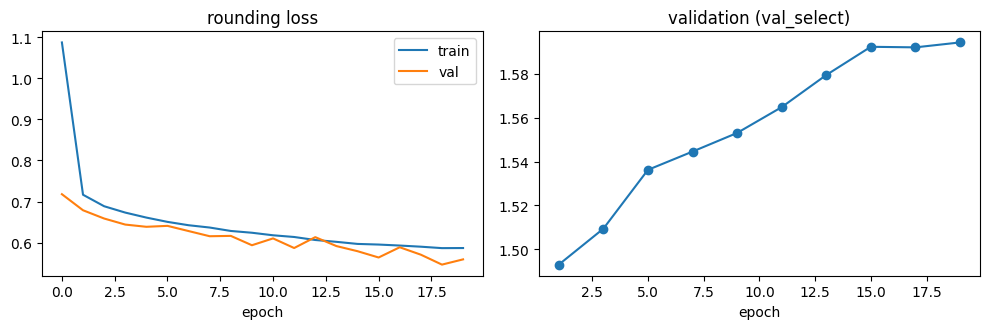

In [19]:
history = None
if V21 is not None and V21["mode"] == CONFIG["label_table"]:
    main_model = V21["model"]
    history = V21["history"]
    print("reusing the v2.1 model as the main model (table:", CONFIG["label_table"], ")")
else:
    seed_everything()
    main_model = LabelDiffusionBundle(CONFIG, D_COND, label_init).to(DEVICE)
    history = train_diffusion(main_model, CONFIG["epochs"], CONFIG, eval_fn=val_select, tag=f"main {CONFIG['label_table']}")

    val_sweep = inference_sweep(main_model, [1.0, 1.5, 2.0], [0.0, 0.5], [0.05, 0.1, 0.2], ("presence", "traj"))
    val_sweep.to_csv(os.path.join(RESULTS_DIR, "val_inference_sweep.csv"), index=False)
    best = val_sweep.iloc[0]
    CONFIG.update(guidance_scale=float(best.guidance), eta=float(best.eta), clamp=str(best.clamp),
                  retrieval_tau=float(best.tau), score_rule=str(best.rule))
    print("selected on validation:", {k: CONFIG[k] for k in ("guidance_scale", "eta", "clamp", "retrieval_tau", "score_rule")})
    display(val_sweep.head(8))
    ckpt_path = os.path.join(CKPT_DIR, f"label_diffusion_v22_{CONFIG['label_table']}.pt")
    torch.save({"model": main_model.state_dict(), "config": CONFIG, "history": history, "d_cond": D_COND}, ckpt_path)
    print("saved", ckpt_path)

if history:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    axes[0].plot(history["train_round"], label="train"); axes[0].plot(history["val_round"], label="val"); axes[0].set_title("rounding loss"); axes[0].legend()
    key = "val_select" if "val_select" in history else "val_P@5"
    ep = [i for i, v in enumerate(history[key]) if not np.isnan(v)]
    axes[1].plot(ep, [history[key][i] for i in ep], "o-"); axes[1].set_title(f"validation ({key})")
    for a in axes: a.set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "training_curves_main.png"), dpi=130); plt.show()
np.save(os.path.join(CKPT_DIR, "label_propensity.npy"), PROPENSITY)
np.save(os.path.join(CKPT_DIR, "label_frequency.npy"), LABEL_FREQ)

### 8d. Deterministic set-MLP baseline (is the diffusion needed?)

Same BERT embedding $h$, same label table (warm start, `full` mode), same slot format (8 slots, NULL padding), same
rounding loss and same score rules &mdash; but **no noise, no timesteps, no iterative denoising, no sampling**: an MLP maps
$h$ directly to the 8 &times; 128 clean set in one shot,
$h\ (768) \to \text{LN} \to 1024 \to 1024 \to 8\times128$.

The slots are an unordered set and an MLP's outputs are ordered, so each prediction is first matched to its targets with
the **Hungarian algorithm** on cosine cost (as in DETR, Carion et al., 2020); the MSE and rounding losses are then
applied to the matched pairs. Without matching, a fixed-order MSE would learn the average label. Its score rule and
temperature are chosen on validation (the `traj` rule needs a trajectory, so it does not apply).

In [20]:
from scipy.optimize import linear_sum_assignment

class SetMLP(nn.Module):
    def __init__(self, d_cond, cfg, label_init):
        super().__init__()
        self.cfg = {**cfg, "label_table": "full"}
        self.M, self.d = cfg["n_slots"], cfg["d_lat"]
        Hd = cfg["mlp_hidden"]
        self.label_space = LabelSpace(cfg["num_labels"] + 1, self.d, label_init)
        self.net = nn.Sequential(nn.LayerNorm(d_cond), nn.Linear(d_cond, Hd), nn.GELU(),
                                 nn.Linear(Hd, Hd), nn.GELU(), nn.Linear(Hd, self.M * self.d))

    def forward(self, h):
        return self.net(h).view(-1, self.M, self.d)


def hungarian_match(pred, tgt):
    # pred, tgt: (B, M, d) -> perm (B, M): pred slot j is matched to target slot perm[b, j]
    cost = -(F.normalize(pred.detach().float(), dim=-1) @ F.normalize(tgt.float(), dim=-1).transpose(1, 2))
    c = cost.cpu().numpy()
    return torch.from_numpy(np.stack([linear_sum_assignment(ci)[1] for ci in c])).to(pred.device)


def setmlp_loss(model, h, slot_labels, pos_mask, cfg):
    ls = model.label_space
    unit = ls.unit_table()
    B, M = slot_labels.shape
    x0_hat = model(h).float()
    tgt_all = (ls.scale * unit[slot_labels]).detach()
    perm = hungarian_match(x0_hat, tgt_all)
    labels = slot_labels.gather(1, perm)
    z0 = tgt_all.gather(1, perm[..., None].expand(-1, -1, tgt_all.shape[-1]))
    w = LABEL_WEIGHTS[labels]
    loss_mse = ((((x0_hat - z0) ** 2).mean(-1)) * w).sum() / w.sum()
    xh = F.normalize(x0_hat, dim=-1).reshape(B * M, -1)
    logits = (xh @ unit.float().T).float() / cfg["round_tau"]
    pm = pos_mask[:, None, :].expand(B, M, pos_mask.shape[1]).reshape(B * M, -1).clone()
    pm.scatter_(1, labels.reshape(-1, 1), False)
    logits = logits.masked_fill(pm, -1e4)
    ce = F.cross_entropy(logits, labels.reshape(-1), reduction="none")
    loss_round = (ce * w.reshape(-1)).sum() / w.sum()
    return loss_mse + cfg["round_weight"] * loss_round, loss_round.detach()


@torch.no_grad()
def predict_topk_mlp(model, H, doc_ids, k=5, variants=None, batch_docs=512):
    model.eval()
    variants = variants or [(MLP_TAU, 0.0, MLP_RULE)]
    unit = model.label_space.unit_table().detach().float()
    outs = [[] for _ in variants]
    for s in range(0, len(doc_ids), batch_docs):
        chunk = torch.as_tensor(np.asarray(doc_ids[s:s + batch_docs]), device=DEVICE)
        x0 = model(H[chunk].float()).float()
        for j, (tau, boost, rule) in enumerate(variants):
            outs[j].extend(rank_from_scores(set_scores(x0, unit, x0.shape[0], 1, tau, rule), k, boost))
    return outs


MLP_RULES = ("presence", "presence_tb", "logabsent", "count")
MLP_TAU, MLP_RULE = 0.1, "presence"
seed_everything()
set_mlp = SetMLP(D_COND, CONFIG, label_init).to(DEVICE)
print(f"set-MLP parameters: {sum(p.numel() for p in set_mlp.net.parameters()):,} + label table {set_mlp.label_space.weight.numel():,}")
M_, bs_ = CONFIG["n_slots"], CONFIG["batch_size"]
n_tr = TRAIN_H.shape[0]
steps_ep = math.ceil(n_tr / bs_)
total_ = CONFIG["mlp_epochs"] * steps_ep
opt_ = torch.optim.AdamW(set_mlp.parameters(), lr=CONFIG["mlp_lr"], weight_decay=CONFIG["weight_decay"])
sched_ = torch.optim.lr_scheduler.LambdaLR(opt_, lambda s: min(1.0, (s + 1) / 200) * (0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * s / total_))))
rng_ = np.random.default_rng(SEED)
best_sel, best_state, t0 = -1.0, None, time.time()
for ep in range(CONFIG["mlp_epochs"]):
    set_mlp.train()
    perm_ = rng_.permutation(n_tr); tot_r = 0.0
    for s in range(steps_ep):
        idx = torch.from_numpy(perm_[s * bs_:(s + 1) * bs_]).to(DEVICE)
        lab = TRAIN_LAB[idx]
        loss, lr_ = setmlp_loss(set_mlp, TRAIN_H[idx].float(), sample_slots(lab, M_), pos_mask_from(lab), CONFIG)
        opt_.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(set_mlp.parameters(), 1.0)
        opt_.step(); sched_.step(); tot_r += float(lr_)
    sel = quick_metrics(predict_topk_mlp(set_mlp, VAL_H, VAL_EVAL_IDS, k=5)[0], VAL_EVAL_LABELS)["select"]
    if sel > best_sel:
        best_sel, best_state = sel, copy.deepcopy(set_mlp.state_dict())
    print(f"[set-MLP] epoch {ep+1}/{CONFIG['mlp_epochs']}  round={tot_r/steps_ep:.4f}  val select={sel:.4f}  {(time.time()-t0)/60:.1f} min")
set_mlp.load_state_dict(best_state)

combos = [(t, 0.0, r) for t in (0.05, 0.1, 0.2, 0.5) for r in MLP_RULES]
outs = predict_topk_mlp(set_mlp, VAL_H, VAL_EVAL_IDS, k=5, variants=combos)
mlp_sweep = pd.DataFrame([dict(tau=t, rule=r, **quick_metrics(p, VAL_EVAL_LABELS)) for (t, _, r), p in zip(combos, outs)])
mlp_sweep = mlp_sweep.sort_values("select", ascending=False).reset_index(drop=True)
MLP_TAU, MLP_RULE = float(mlp_sweep.iloc[0].tau), str(mlp_sweep.iloc[0].rule)
print("set-MLP settings selected on validation:", {"tau": MLP_TAU, "rule": MLP_RULE})
display(mlp_sweep.head(6))
torch.save({"model": set_mlp.state_dict(), "tau": MLP_TAU, "rule": MLP_RULE}, os.path.join(CKPT_DIR, "set_mlp_baseline.pt"))

set-MLP parameters: 2,888,192 + label table 1,706,368
[set-MLP] epoch 1/10  round=1.6320  val select=1.5857  1.5 min
[set-MLP] epoch 2/10  round=1.3613  val select=1.5966  3.1 min
[set-MLP] epoch 3/10  round=1.3135  val select=1.6062  4.6 min
[set-MLP] epoch 4/10  round=1.2782  val select=1.6129  6.2 min
[set-MLP] epoch 5/10  round=1.2469  val select=1.6211  7.7 min
[set-MLP] epoch 6/10  round=1.2178  val select=1.6241  9.3 min
[set-MLP] epoch 7/10  round=1.1907  val select=1.6273  10.8 min
[set-MLP] epoch 8/10  round=1.1668  val select=1.6283  12.4 min
[set-MLP] epoch 9/10  round=1.1490  val select=1.6288  13.9 min
[set-MLP] epoch 10/10  round=1.1377  val select=1.6292  15.5 min
set-MLP settings selected on validation: {'tau': 0.05, 'rule': 'presence'}


,tau,rule,P@1,P@3,P@5,nDCG@5,PSP@5,PSnDCG@5,tail recall@5,select
0,0.05,presence,0.9535,0.818333,0.6590,0.880899,0.803825,0.752095,0.103448,1.632994
1,0.05,presence_tb,0.9535,0.818333,0.6590,0.880899,0.803825,0.752095,0.103448,1.632994
2,0.05,logabsent,0.9535,0.818333,0.6590,0.880899,0.803825,0.752095,0.103448,1.632994
3,0.10,presence,0.9570,0.821500,0.6594,0.882486,0.788378,0.746725,0.000000,1.629211
4,0.10,logabsent,0.9570,0.821500,0.6594,0.882486,0.788378,0.746725,0.000000,1.629211
5,0.10,presence_tb,0.9570,0.821500,0.6594,0.882486,0.788378,0.746725,0.000000,1.629211


In [21]:
test_doc_ids = np.arange(len(test_labels))
t0 = time.time()
diffusion_preds = predict_topk(main_model, TEST_H, test_doc_ids, k=max(CONFIG["ks"]))
print(f"diffusion predictions for {len(test_doc_ids)} test docs in {time.time()-t0:.1f}s")
baseline_preds = predict_topk_baseline(TEST_H, test_doc_ids, k=max(CONFIG["ks"]))
print("example (top-5):", diffusion_preds[0], "| baseline:", baseline_preds[0], "| true:", test_labels[0])

mlp_preds = predict_topk_mlp(set_mlp, TEST_H, test_doc_ids, k=max(CONFIG["ks"]))[0]

# FAISS retrieval path: only the top-m nearest labels of each generated slot are scored (softmax over those m),
# then aggregated with the "presence" rule and compared with the exact path under the same rule. Overlap is < 1 partly
# because the noise draws differ (the exact path batches documents differently) and ranks 3-5 are often near-ties.
try:
    import faiss
    faiss.omp_set_num_threads(1)          # avoid OpenMP contention with PyTorch in the same process
    unit_t = main_model.label_space.unit_table().detach().float()
    unit_np = unit_t.cpu().numpy()[:L_].copy()
    unit_np[ABSENT] = 0.0
    index = faiss.IndexFlatIP(unit_np.shape[1]); index.add(unit_np)
    ids200 = test_doc_ids[:200]; K, M, m_top = CONFIG["K_samples"], CONFIG["n_slots"], 50
    gen = torch.Generator(device=DEVICE); gen.manual_seed(0)
    x0 = diffusion.sample(main_model, TEST_H[torch.as_tensor(ids200, device=DEVICE)].float().repeat_interleave(K, 0),
                          M, CONFIG["ddim_steps"], CONFIG["guidance_scale"], CONFIG["eta"], CONFIG["clamp"], gen)
    q = F.normalize(x0.reshape(-1, x0.shape[-1]), dim=-1)
    null_sim = (q @ unit_t[L_]).cpu().numpy()                       # NULL competes in the softmax, as in the exact path
    D_, I_ = index.search(q.cpu().numpy().astype("float32"), m_top)
    logits = np.concatenate([D_, null_sim[:, None]], 1) / CONFIG["retrieval_tau"]
    P = np.exp(logits - logits.max(1, keepdims=True)); P = (P / P.sum(1, keepdims=True))[:, :m_top]
    P, I_ = P.reshape(len(ids200), K, M * m_top), I_.reshape(len(ids200), K, M * m_top)
    faiss_preds = []
    for b in range(len(ids200)):
        score = {}
        for k in range(K):
            log_absent = {}
            for l, p in zip(I_[b, k], P[b, k]):
                log_absent[l] = log_absent.get(l, 0.0) + np.log1p(-min(p, 1 - 1e-6))
            for l, la in log_absent.items():
                score[l] = score.get(l, 0.0) + (1 - np.exp(la)) / K
        faiss_preds.append([l for l, _ in sorted(score.items(), key=lambda x: -x[1])[:5]])
    exact = predict_topk(main_model, TEST_H, ids200, k=5, variants=[(CONFIG["retrieval_tau"], 0.0, "presence")])[0]
    agree = np.mean([len(set(a) & set(b)) / 5 for a, b in zip(faiss_preds, exact)])
    print(f"FAISS path OK; top-5 overlap with the exact path on 200 docs (different noise draws): {agree:.2f}")
except ImportError:
    print("faiss not importable - torch path used everywhere else")

diffusion predictions for 30000 test docs in 109.5s
example (top-5): [10063, 7961, 9237, 2495, 3088] | baseline: [7961, 10063, 9237, 2495, 3088] | true: [7961, 9237, 10063]
FAISS path OK; top-5 overlap with the exact path on 200 docs (different noise draws): 0.95


## 9. Quantitative, Tail-Label and Efficiency Evaluation

Same metrics as v1 (P@k, nDCG@k, un-normalised PSP@k, PSnDCG@k, recall by label-frequency band),
on the same-size test subsample. **Both rows use the same fine-tuned BERT embeddings.**

,P@1,P@3,P@5,nDCG@1,nDCG@3,nDCG@5,PSP@1,PSP@3,PSP@5,PSnDCG@1,PSnDCG@3,PSnDCG@5
method,,,,,,,,,,,,
"v2.2 label-diffusion (full, traj; LoRA, 256 tok, 100% train)",0.9031,0.7845,0.6335,0.9031,0.8648,0.8451,1.0491,0.9262,0.7748,0.6686,0.7063,0.7312
"v2.2 set-MLP, deterministic (presence; LoRA, 256 tok, 100% train)",0.9564,0.8135,0.6515,0.9564,0.9034,0.8773,0.9985,0.9174,0.7926,0.6594,0.7071,0.7420
"v2.2 BERT + linear head (LoRA, 256 tok, 100% train)",0.9486,0.8073,0.6559,0.9486,0.8962,0.8775,1.1269,0.9981,0.8359,0.7033,0.7446,0.7705


true-label occurrences per band in the evaluated test docs: {'tail': 794, 'torso': 6043, 'head': 146638}


,recall@5 [tail],recall@5 [torso],recall@5 [head]
method,,,
"v2.2 label-diffusion (full, traj; LoRA, 256 tok, 100% train)",0.0000,0.2254,0.6387
"v2.2 set-MLP, deterministic (presence; LoRA, 256 tok, 100% train)",0.0101,0.2704,0.6552
"v2.2 BERT + linear head (LoRA, 256 tok, 100% train)",0.0844,0.4769,0.6509


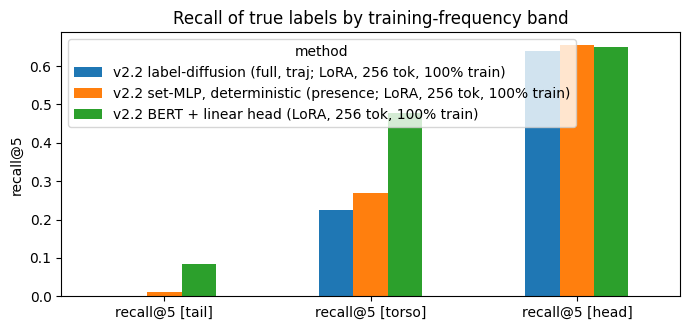

In [22]:
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
ENC = f"{'LoRA' if CONFIG['bert_tuning'] == 'lora' else 'full FT'}, {CONFIG['max_len']} tok, {int(round(CONFIG['train_fraction']*100))}% train"
MAIN_NAME = f"v2.2 label-diffusion ({CONFIG['label_table']}, {CONFIG['score_rule']}; {ENC})"
eval_sets = [(MAIN_NAME, diffusion_preds),
             (f"v2.2 set-MLP, deterministic ({MLP_RULE}; {ENC})", mlp_preds),
             (f"v2.2 BERT + linear head ({ENC})", baseline_preds)]
results_df = pd.DataFrame([full_report(n, p, test_labels, CONFIG["ks"]) for n, p in eval_sets]).set_index("method")
results_df.to_csv(os.path.join(RESULTS_DIR, "accuracy_metrics.csv"))
display(results_df)

BANDS = {"tail": TAIL_MASK, "torso": TORSO_MASK, "head": HEAD_MASK}
band_rows = []
for name, preds in eval_sets:
    rec, counts = band_recall_at_k(preds, test_labels, BANDS, k=5)
    band_rows.append({"method": name, **{f"recall@5 [{b}]": v for b, v in rec.items()}})
band_df = pd.DataFrame(band_rows).set_index("method")
band_df.to_csv(os.path.join(RESULTS_DIR, "recall_by_label_band.csv"))
print("true-label occurrences per band in the evaluated test docs:", counts)
display(band_df)
ax = band_df.T.plot(kind="bar", figsize=(7, 3.4), rot=0)
ax.set_ylabel("recall@5"); ax.set_title("Recall of true labels by training-frequency band")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "recall_by_band.png"), dpi=130); plt.show()

### Head vs tail trade-off (propensity re-ranking)

The same $\beta$ = `tail_boost` re-ranking is applied to both models. $\beta = 0$ optimises plain P@k;
larger $\beta$ trades head precision for tail recall and PSP@k. Pick the operating point the report
argues for, and use the same $\beta$ for both methods when comparing.

,method,tail_boost,P@1,P@5,PSP@5,tail recall@5,torso recall@5
0,diffusion,0.0000,0.9031,0.6335,0.7748,0.0000,0.2254
1,BERT + head,0.0000,0.9486,0.6559,0.8359,0.0844,0.4769
2,diffusion,0.2500,0.8854,0.6324,0.7762,0.0000,0.2393
3,BERT + head,0.2500,0.9222,0.6542,0.8467,0.1121,0.5383
4,diffusion,0.5000,0.8679,0.6309,0.7778,0.0000,0.2565
5,BERT + head,0.5000,0.8998,0.6517,0.8531,0.1373,0.5777
6,diffusion,1.0000,0.8386,0.6271,0.7796,0.0000,0.2932
7,BERT + head,1.0000,0.8625,0.6426,0.8584,0.1877,0.6444


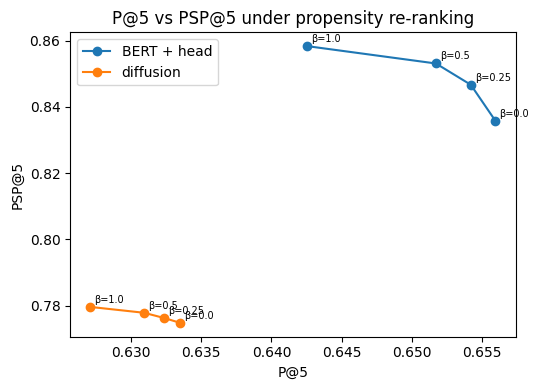

In [23]:
boosts = [0.0, 0.25, 0.5, 1.0]
tb_rows = []
diff_outs = predict_topk(main_model, TEST_H, test_doc_ids, k=5, variants=[(CONFIG["retrieval_tau"], b) for b in boosts])
for b, dp in zip(boosts, diff_outs):
    bp = predict_topk_baseline(TEST_H, test_doc_ids, k=5, tail_boost=b)
    for name, preds in [("diffusion", dp), ("BERT + head", bp)]:
        rec, _ = band_recall_at_k(preds, test_labels, {"tail": TAIL_MASK, "torso": TORSO_MASK}, k=5)
        tb_rows.append({"method": name, "tail_boost": b, "P@1": precision_at_k(preds, test_labels, (1,))[1],
                        "P@5": precision_at_k(preds, test_labels, (5,))[5],
                        "PSP@5": psp_at_k(preds, test_labels, PROPENSITY, (5,))[5],
                        "tail recall@5": rec["tail"], "torso recall@5": rec["torso"]})
tail_boost_df = pd.DataFrame(tb_rows)
tail_boost_df.to_csv(os.path.join(RESULTS_DIR, "tail_boost_tradeoff.csv"), index=False)
display(tail_boost_df)

fig, ax = plt.subplots(figsize=(5.5, 4))
for name, g in tail_boost_df.groupby("method"):
    ax.plot(g["P@5"], g["PSP@5"], "o-", label=name)
    for _, r in g.iterrows():
        ax.annotate(f"β={r.tail_boost}", (r["P@5"], r["PSP@5"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("P@5"); ax.set_ylabel("PSP@5"); ax.set_title("P@5 vs PSP@5 under propensity re-ranking"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "tail_boost_tradeoff.png"), dpi=130); plt.show()

In [24]:
def timed(fn, label, n_docs=500):
    ids = test_doc_ids[:min(n_docs, len(test_doc_ids))]
    fn(ids[:min(32, len(ids))])
    if DEVICE == "cuda":
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time(); fn(ids)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    dt = time.time() - t0
    peak = torch.cuda.max_memory_allocated() / 1e6 if DEVICE == "cuda" else float("nan")
    return {"method": label, "ms_per_doc": 1000 * dt / len(ids), "peak_gpu_MB": peak}

n_bert = sum(p.numel() for p in bert_xmc.bert.parameters())
n_diff = sum(p.numel() for p in main_model.parameters())
n_head = sum(p.numel() for p in bert_xmc.head.parameters())
eff_rows = [
    {**timed(lambda ids: encode_docs(bert_xmc, test_ids_np[ids], CONFIG["encode_batch"], verbose=False), "BERT encoder (shared by both)"), "parameters": n_bert},
    {**timed(lambda ids: predict_topk(main_model, TEST_H, ids, k=5),
             f"diffusion stage (K={CONFIG['K_samples']}, M={CONFIG['n_slots']}, {CONFIG['ddim_steps']} steps)"), "parameters": n_diff},
    {**timed(lambda ids: predict_topk(main_model, TEST_H, ids, k=5, K_samples=2, ddim_steps=4), "diffusion stage (fast: K=2, 4 steps)"), "parameters": n_diff},
    {**timed(lambda ids: predict_topk_mlp(set_mlp, TEST_H, ids, k=5), "set-MLP stage"), "parameters": sum(p.numel() for p in set_mlp.parameters())},
    {**timed(lambda ids: predict_topk_baseline(TEST_H, ids, k=5), "linear head stage"), "parameters": n_head},
]
eff_df = pd.DataFrame(eff_rows).set_index("method")
eff_df.to_csv(os.path.join(RESULTS_DIR, "efficiency_metrics.csv"))
eff_df

,ms_per_doc,peak_gpu_MB,parameters
method,,,
BERT encoder (shared by both),1.5343,3571.7765,109482240
"diffusion stage (K=4, M=8, 10 steps)",3.6194,3881.4254,14715648
"diffusion stage (fast: K=2, 4 steps)",0.7185,3874.7510,14715648
set-MLP stage,0.0413,3837.8614,4594560
linear head stage,0.0107,3243.1857,10250770


## 10. Ablation Study

Inference-time knobs reuse the trained model (test subsample of 2,000 docs, same as v1). Training-time
variants are **retrained with a reduced budget** (`ablation_epochs` on `ablation_max_docs` documents)
and should be compared only with each other.

| Training-time variant | What it isolates |
|---|---|
| full recipe | reference for the retrained rows (uses the selected `label_table` mode) |
| no self-conditioning | value of feeding the previous x0 estimate back in |
| 1 slot (no label&ndash;label attention) | the v1 formulation (one label per sample) inside the same network: value of **set** diffusion / modelling label correlations |
| no rounding loss | value of the identifiability loss for the denoiser |
| random label init | value of the BERT-PIFA + co-occurrence warm start (with `frozen`, the table stays random) |

The label-table modes themselves are compared in Section 8b (on validation), and the score rules in 8d (validation) and
below (test, `score_rule` axis).

In [25]:
ablation_doc_ids = test_doc_ids[:min(2000, len(test_doc_ids))]
ablation_labels = [test_labels[i] for i in ablation_doc_ids]

def eval_preds(preds):
    p = precision_at_k(preds, ablation_labels, (1, 5))
    rec, _ = band_recall_at_k(preds, ablation_labels, {"tail": TAIL_MASK}, k=5)
    return {"P@1": p[1], "P@5": p[5], "PSP@5": psp_at_k(preds, ablation_labels, PROPENSITY, (5,))[5], "tail recall@5": rec["tail"]}

def run_inference_ablation(axis, values, key):
    rows = []
    for v in values:
        t0 = time.time()
        preds = predict_topk(main_model, TEST_H, ablation_doc_ids, k=5, **{key: v})
        rows.append({"axis": axis, "value": str(v), **eval_preds(preds), "ms/doc": 1000 * (time.time() - t0) / len(ablation_doc_ids)})
    return rows

ablation_df = None
if CONFIG["run_inference_ablations"]:
    ablation_rows = []
    rule_outs = predict_topk(main_model, TEST_H, ablation_doc_ids, k=5, variants=[(CONFIG["retrieval_tau"], 0.0, r) for r in SCORE_RULES])
    ablation_rows += [{"axis": "score_rule", "value": r, **eval_preds(p), "ms/doc": float("nan")} for r, p in zip(SCORE_RULES, rule_outs)]
    ablation_rows += run_inference_ablation("ddim_steps", [2, 5, 10, 20, 50], "ddim_steps")
    ablation_rows += run_inference_ablation("K_samples", [1, 2, 4, 8, 16], "K_samples")
    ablation_rows += run_inference_ablation("guidance", [0.0, 1.0, 1.5, 3.0], "guidance")
    ablation_rows += run_inference_ablation("clamp", ["none", "hard"], "clamp")
    ablation_df = pd.DataFrame(ablation_rows)
    ablation_df.to_csv(os.path.join(RESULTS_DIR, "ablation_inference.csv"), index=False)
    display(ablation_df)
else:
    print("inference ablations skipped (reported from the v2.1 run)")

inference ablations skipped (reported from the v2.1 run)


In [26]:
train_abl_df = None
if not CONFIG["run_training_ablations"]:
    print("training-time ablations skipped (reported from the v2.1 run)")
    variants = {}
rng = np.random.default_rng(SEED)
abl_docs = rng.permutation(TRAIN_H.shape[0])[:CONFIG["ablation_max_docs"]]
print(f"retraining variants on {len(abl_docs):,} docs for {CONFIG['ablation_epochs']} epochs each")
rand_init = random_label_init(L_ + 1, CONFIG["d_lat"])
variants = {} if not CONFIG["run_training_ablations"] else {
    "full recipe":                      (dict(), label_init, None),
    "no self-conditioning":             (dict(self_cond=False), label_init, None),
    "1 slot (no label-label attention)":(dict(n_slots=1), label_init, None),
    "no rounding loss":                 (dict(), label_init, 0.0),
    "random label init":                (dict(), rand_init, None),
}
train_rows = []
for name, (over, init, rw) in variants.items():
    seed_everything()
    cfg_v = {**CONFIG, **over}
    m = LabelDiffusionBundle(cfg_v, D_COND, init).to(DEVICE)
    train_diffusion(m, CONFIG["ablation_epochs"], cfg_v, doc_subset=abl_docs, round_weight=rw, tag=name[:20])
    K_eq = max(1, CONFIG["K_samples"] * CONFIG["n_slots"] // cfg_v["n_slots"])     # same number of label draws
    preds = predict_topk(m, TEST_H, ablation_doc_ids, k=5, K_samples=K_eq)
    train_rows.append({"axis": "training-time (retrained)", "value": name, **eval_preds(preds)})
    del m; gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
if train_rows:
    train_abl_df = pd.DataFrame(train_rows)
    train_abl_df.to_csv(os.path.join(RESULTS_DIR, "ablation_training.csv"), index=False)
    display(train_abl_df)

training-time ablations skipped (reported from the v2.1 run)
retraining variants on 150,000 docs for 6 epochs each


In [27]:
if ablation_df is not None and train_abl_df is not None:
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
    d = ablation_df[ablation_df.axis == "ddim_steps"]
    axes[0].plot(d["ms/doc"], d["P@5"], "o-")
    for _, r in d.iterrows():
        axes[0].annotate(r["value"], (r["ms/doc"], r["P@5"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    axes[0].set_xlabel("latency of diffusion stage (ms/doc)"); axes[0].set_ylabel("P@5"); axes[0].set_title("DDIM steps")
    d = ablation_df[ablation_df.axis == "K_samples"]
    axes[1].plot(d["value"].astype(int), d["P@5"], "o-", label="P@5"); axes[1].plot(d["value"].astype(int), d["PSP@5"], "s--", label="PSP@5")
    axes[1].set_xscale("log", base=2); axes[1].set_xlabel("label sets sampled per doc"); axes[1].set_title("Accuracy vs K"); axes[1].legend()
    d = ablation_df[ablation_df.axis == "guidance"]
    axes[2].bar(d["value"], d["P@5"]); axes[2].set_xlabel("guidance (0 = document ignored)"); axes[2].set_title("Conditioning")
    axes[3].barh(train_abl_df["value"], train_abl_df["P@5"]); axes[3].set_title("Training-time ablations (P@5)")
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "ablation_plots.png"), dpi=130); plt.show()

## 11. Qualitative Results

In [28]:
def name_of(l):
    return LABEL_NAMES[l] if LABEL_NAMES else str(l)

def show_qualitative(n=8, seed=0):
    rng = np.random.default_rng(seed)
    for i in rng.choice(len(test_doc_ids), size=min(n, len(test_doc_ids)), replace=False):
        true = set(test_labels[i]); pred = diffusion_preds[i]
        print(f"doc #{i}: \"{test_texts[i][:140].replace(chr(10), ' ')}...\"")
        print(f"   true labels:          {[name_of(l) for l in sorted(true)]}")
        print(f"   diffusion top-5:      {[name_of(l) for l in pred]}")
        print(f"   baseline top-5:       {[name_of(l) for l in baseline_preds[i]]}")
        print(f"   diffusion recovered:  {[name_of(l) for l in sorted(true & set(pred))]}  "
              f"tail hits: {[name_of(l) for l in pred if l in true and TAIL_MASK[l]]}")
        print()

show_qualitative(8)

doc #25512: "The Following Generation  The sound of a solo voice soothes and captivates the listener in this collection of Navajo prayer songs. In the ti..."
   true labels:          ['7961', '9237', '13259']
   diffusion top-5:      ['7961', '13259', '2420', '9237', '4856']
   baseline top-5:       ['7961', '13259', '9237', '8109', '2420']
   diffusion recovered:  ['7961', '9237', '13259']  tail hits: []

doc #2257: "Honey (Dts)  This DTS CD is an out of print collectible! It is a DTS Entertainment release. Catalog 71021-54404-2-2. There is a saw cut on t..."
   true labels:          ['7961', '9237', '9678']
   diffusion top-5:      ['7961', '9237', '10063', '2495', '9678']
   baseline top-5:       ['7961', '9237', '10063', '9678', '3322']
   diffusion recovered:  ['7961', '9237', '9678']  tail hits: []

doc #495: "VeggieTales - God Wants Me to Forgive Them? [VHS] (1998)  Another early entry in the VeggieTales series offers two lessons on forgiveness. T..."
   true labels:          ['

## 12. Interactive Demo (in-notebook prototype)

Raw text &rarr; BERT &rarr; set diffusion &rarr; retrieval, with sliders for steps and samples. Works only in an
interactive session. The saved `bert_xmc_*.pt` and `label_diffusion_v21.pt` checkpoints are everything a
standalone Gradio app needs.

In [29]:
import ipywidgets as widgets

@torch.no_grad()
def predict_raw_text(raw_text, k=5, K_samples=None, ddim_steps=None):
    ids = tokenize_all([raw_text], CONFIG["max_len"], verbose=False)
    ids_t, mask = to_device_batch(ids)
    bert_xmc.eval()
    with autocast():
        h = bert_xmc(ids_t, mask, pooled_only=True).float()
    return predict_topk(main_model, h, np.array([0]), k=k, K_samples=K_samples, ddim_steps=ddim_steps)[0]

text_box = widgets.Textarea(value=test_texts[0][:300] if len(test_texts) else "type a product description",
                            description="document:", layout=widgets.Layout(width="650px", height="90px"))
k_slider = widgets.IntSlider(value=5, min=1, max=10, description="top-k")
steps_slider = widgets.IntSlider(value=CONFIG["ddim_steps"], min=2, max=50, description="DDIM steps")
samples_slider = widgets.IntSlider(value=CONFIG["K_samples"], min=1, max=16, description="K sets")
button = widgets.Button(description="Predict", button_style="primary")
out = widgets.Output()

def on_click(_):
    out.clear_output()
    with out:
        t0 = time.time()
        preds = predict_raw_text(text_box.value, k=k_slider.value, K_samples=samples_slider.value, ddim_steps=steps_slider.value)
        print("predicted labels:", [name_of(l) for l in preds], f"({1000*(time.time()-t0):.1f} ms)")

button.on_click(on_click)
display(widgets.VBox([text_box, widgets.HBox([k_slider, steps_slider, samples_slider]), button, out]))
on_click(None)

## 13. v1 &rarr; v2 &rarr; v2.1 &rarr; v2.2 Summary, Limitations & Next Steps

In [30]:
# v1 and v2 numbers copied from those notebook runs (same 30,000-doc test subsample size and seed)
earlier = pd.DataFrame([
    {"method": "v1 label-diffusion (TF-IDF, 30% train)",   "P@1": 0.8295, "P@3": 0.6413, "P@5": 0.4782, "PSP@5": 0.5749, "tail recall@5": 0.0000},
    {"method": "v1 direct classifier (TF-IDF, 30% train)", "P@1": 0.9009, "P@3": 0.7273, "P@5": 0.5759, "PSP@5": 0.8077, "tail recall@5": 0.1614},
    {"method": "v2 label-diffusion (BERT, 50% train)",     "P@1": 0.8740, "P@3": 0.7782, "P@5": 0.6210, "PSP@5": 0.7991, "tail recall@5": 0.0013},
    {"method": "v2 BERT + linear head (50% train)",        "P@1": 0.9499, "P@3": 0.8048, "P@5": 0.6526, "PSP@5": 0.8884, "tail recall@5": 0.1292},
    {"method": "v2.1 label-diffusion (full, traj)",        "P@1": 0.9075, "P@3": 0.7852, "P@5": 0.6317, "PSP@5": 0.8345, "tail recall@5": 0.0032},
]).set_index("method")
now = results_df[["P@1", "P@3", "P@5", "PSP@5"]].copy()
now["tail recall@5"] = band_df["recall@5 [tail]"].values
summary = pd.concat([earlier, now])
summary.to_csv(os.path.join(RESULTS_DIR, "v1_to_v22_summary.csv"))
print("note: training pool / encoder differ between versions (v1: 30%, TF-IDF; v2-v2.1: 50%, 128 tokens, full fine-tuning;"
      " v2.2: see row names). Compare diffusion vs baselines WITHIN a version; across versions, data and encoder also changed.")
summary

note: training pool / encoder differ between versions (v1: 30%, TF-IDF; v2-v2.1: 50%, 128 tokens, full fine-tuning; v2.2: see row names). Compare diffusion vs baselines WITHIN a version; across versions, data and encoder also changed.


,P@1,P@3,P@5,PSP@5,tail recall@5
method,,,,,
"v1 label-diffusion (TF-IDF, 30% train)",0.8295,0.6413,0.4782,0.5749,0.0000
"v1 direct classifier (TF-IDF, 30% train)",0.9009,0.7273,0.5759,0.8077,0.1614
"v2 label-diffusion (BERT, 50% train)",0.8740,0.7782,0.6210,0.7991,0.0013
v2 BERT + linear head (50% train),0.9499,0.8048,0.6526,0.8884,0.1292
"v2.1 label-diffusion (full, traj)",0.9075,0.7852,0.6317,0.8345,0.0032
"v2.2 label-diffusion (full, traj; LoRA, 256 tok, 100% train)",0.9031,0.7845,0.6335,0.7748,0.0000
"v2.2 set-MLP, deterministic (presence; LoRA, 256 tok, 100% train)",0.9564,0.8135,0.6515,0.7926,0.0101
"v2.2 BERT + linear head (LoRA, 256 tok, 100% train)",0.9486,0.8073,0.6559,0.8359,0.0844


**Limitations, stated plainly**
- The BERT encoder is fine-tuned with an auxiliary $L$-way BCE head and then frozen for the diffusion
  stage. The diffusion path never uses that head at inference, but its embeddings were shaped by it. Setting
  `bert_mode="frozen"` removes this dependence (at a large accuracy cost); fine-tuning BERT end-to-end
  through the diffusion loss is the principled next step but costs a BERT forward/backward per diffusion step.
- A BERT + linear head is a strong baseline on AmazonCat-13K, which is head-heavy (about 449 training documents per label). If the diffusion
  model does not beat it on P@k, that is a reportable result; the method's case then rests on the
  label-set view (ablation: 1 slot vs M slots), cost independent of $L$, and the head/tail trade-off.
- `max_len=128` and one fine-tuning epoch on half the training set are budget choices for Kaggle; published BERT-based XMC
  systems train longer, use the full data, and use label clustering/shortlisting.
- Labels beyond $M$ = `n_slots` in a document are only seen as a random subset per epoch.
- The rounding loss uses a full softmax over labels at training time (fine at 13K labels; would need sampled
  negatives at 670K). The flat retrieval index is exhaustive over $d_{lat}$-dim label vectors; use IVF/HNSW at larger scale.

**Next steps:** full training set and 2&ndash;3 BERT epochs; end-to-end fine-tuning through the diffusion loss;
Wiki10-31K / Amazon-670K for tail-heavy evaluation; discrete (absorbing-state) diffusion over label sets as a second formulation.

## References

Nicolas Carion, Francisco Massa, Gabriel Synnaeve, Nicolas Usunier, Alexander Kirillov and Sergey Zagoruyko. End-to-End Object Detection with Transformers (DETR), ECCV, 2020. https://arxiv.org/abs/2005.12872

Jacob Devlin, Ming-Wei Chang, Kenton Lee and Kristina Toutanova. BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding, NAACL, 2019. https://arxiv.org/abs/1810.04805

Wei-Cheng Chang, Hsiang-Fu Yu, Kai Zhong, Yiming Yang and Inderjit Dhillon. Taming Pretrained Transformers for Extreme Multi-label Text Classification (X-Transformer), KDD, 2020. https://arxiv.org/abs/1905.02331

Ting Jiang, Deqing Wang, Leilei Sun, Huayi Yang, Zhengyang Zhao and Fuzhen Zhuang. LightXML: Transformer with Dynamic Negative Sampling for High-Performance Extreme Multi-label Text Classification, AAAI, 2021. https://arxiv.org/abs/2101.03305

Ting Chen, Ruixiang Zhang and Geoffrey Hinton. Analog Bits: Generating Discrete Data using Diffusion Models with Self-Conditioning, ICLR, 2023. https://arxiv.org/abs/2208.04202

William Peebles and Saining Xie. Scalable Diffusion Models with Transformers (DiT), ICCV, 2023. https://arxiv.org/abs/2212.09748

Juho Lee, Yoonho Lee, Jungtaek Kim, Adam Kosiorek, Seungjin Choi and Yee Whye Teh. Set Transformer, ICML, 2019. https://arxiv.org/abs/1810.00825

Xiang Lisa Li, John Thickstun, Ishaan Gulrajani, Percy Liang and Tatsunori B. Hashimoto. Diffusion-LM Improves Controllable Text Generation, NeurIPS, 2022. https://arxiv.org/abs/2205.14217

Xizewen Han, Huangjie Zheng and Mingyuan Zhou. CARD: Classification and Regression Diffusion Models, NeurIPS, 2022. https://arxiv.org/abs/2206.07275

Jonathan Ho, Ajay Jain and Pieter Abbeel. Denoising Diffusion Probabilistic Models, NeurIPS, 2020. https://arxiv.org/abs/2006.11239

Alex Nichol and Prafulla Dhariwal. Improved Denoising Diffusion Probabilistic Models, ICML, 2021. https://arxiv.org/abs/2102.09672

Jiaming Song, Chenlin Meng and Stefano Ermon. Denoising Diffusion Implicit Models, ICLR, 2021. https://arxiv.org/abs/2010.02502

Jonathan Ho and Tim Salimans. Classifier-Free Diffusion Guidance, NeurIPS Workshop, 2021. https://arxiv.org/abs/2207.12598

Himanshu Jain, Yashoteja Prabhu and Manik Varma. Extreme Multi-label Loss Functions for Recommendation, Tagging, Ranking and Other Missing Label Applications, KDD, 2016.

Julian McAuley and Jure Leskovec. Hidden Factors and Hidden Topics: Understanding Rating Dimensions with Review Text, RecSys, 2013.

Ronghui You et al. AttentionXML: Label Tree-based Attention-Aware Deep Model for High-Performance Extreme Multi-Label Text Classification, NeurIPS, 2019. https://arxiv.org/abs/1811.01727

Jeff Johnson, Matthijs Douze and Herve Jegou. Billion-scale Similarity Search with GPUs, IEEE Transactions on Big Data, 2019. https://arxiv.org/abs/1702.08734

Kush Bhatia et al. The Extreme Classification Repository. http://manikvarma.org/downloads/XC/XMLRepository.html

Pietro Lesci. https://huggingface.co/datasets/pietrolesci/amazoncat-13k